# Cheung Methods 

2026/5/13

Extracted SBH by Cheung Methods

originally part of the prev notebook `schottky_cheung.ipynb`


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib_scalebar.scalebar import ScaleBar

# 設置 matplotlib 使用 Arial 字體
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,
    'axes.labelsize': 18,
    'axes.titlesize': 18,
    'axes.titleweight': 'bold',
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'figure.titlesize': 20,
    'figure.titleweight': 'bold'
})

import h5py
import sys
from pathlib import Path

import os

# 導入模組
from ivs_tools.io.h5utils import HDF5Analyzer
#from ivs_tools.physics.schottky_analyzer import SchottkyAnalyzer

root_path  ='/home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2'
filename = "2 um 100 pix bias spec map2.h5"

h5map_path = os.path.join(root_path, filename)

# 初始化 (自動載入)
h5map = HDF5Analyzer(h5map_path)

# 查看結構
h5map.list_structure()

# 取得摘要
print("\nSummary:")
summary = h5map.summary()

h5map.print_usage()

DATASET: bias (Shape: (500,), Dtype: float64)
DATASET: current_fwd (Shape: (500, 10000), Dtype: float64)

METADATA:
  Experiment: Bias-Spectroscopy-Current-Map-fwd
  Bias Points: 500
  Pixels: 100 x 100
  Range: 2.00e-06 x 2.00e-06 m

Summary:
📋 數據摘要
----------------------------------------
文件: 2 um 100 pix bias spec map2.h5
路徑: /home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2/2 um 100 pix bias spec map2.h5

📐 空間維度:
  X方向像素: 100
  Y方向像素: 100

⚡ 偏壓維度:
  偏壓點數: 500
  偏壓範圍: -2.000 到 2.000 V

💾 數據陣列:
  Current Map: (500, 10000) (float64)
    總大小: 38.15 MB
    範圍: -4.328e-05 到 3.409e-05 A
  Bias Vector: (500,) (float64)
----------------------------------------
HDF5Analyzer 使用指南

📁 數據屬性:
----------------------------------------
  • filepath: 未加載或不可用
  • metadata: 未加載或不可用
  • current_map: 未加載或不可用
  • bias_vector: 未加載或不可用

⚙️ 主要方法:
----------------------------------------
  • load_metadata(): 加載元數據
  • load_current_map(): 加載電流映射
  • load_bias_vector(): 加載偏壓序列
  • l

成功載入文件: /home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2/2 um 100 pix bias spec map2.h5

Testing Point 1: (x=87, y=79)


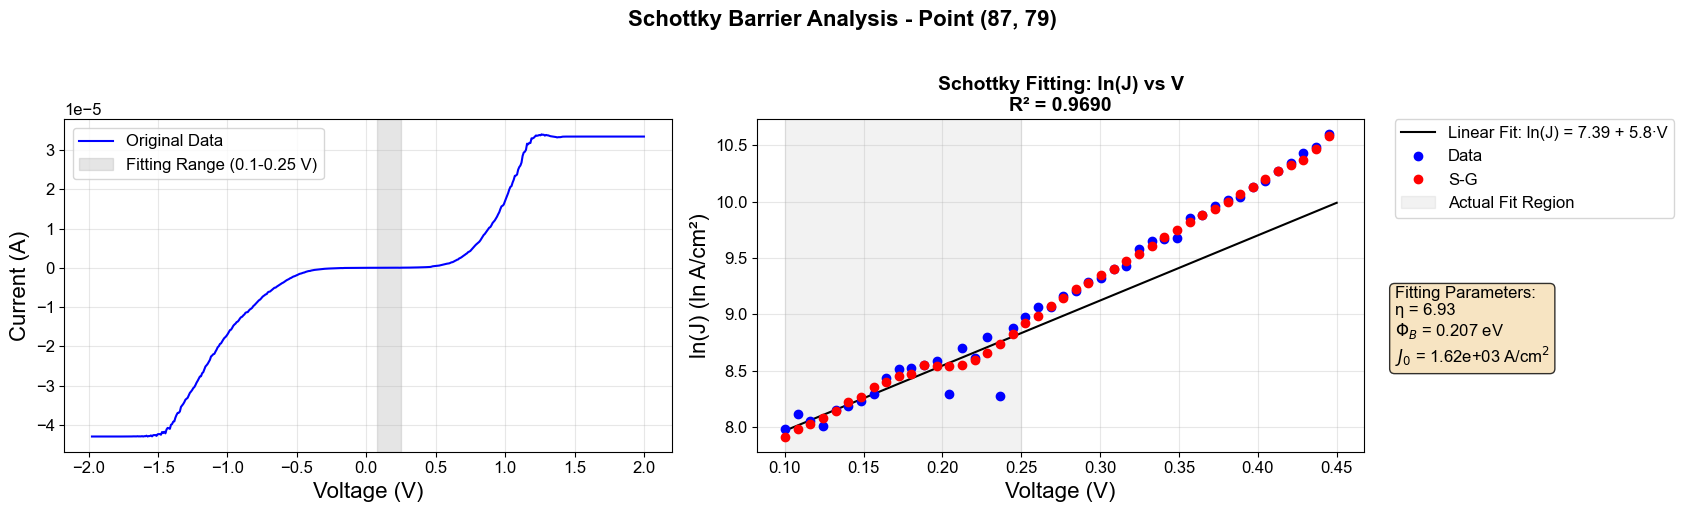

In [2]:
from scipy.signal import savgol_filter

# 載入 HDF5 數據
h5map = HDF5Analyzer(h5map_path)
print(f"成功載入文件: {h5map_path}")

# 選擇一個點進行測試
test_points = [(87, 79)]

for point_idx, (x, y) in enumerate(test_points):
    print(f"\n{'='*60}")
    print(f"Testing Point {point_idx+1}: (x={x}, y={y})")
    print('='*60)
    
    # 獲取 spectrum (跳過前面3個點)
    spectrum = h5map.get_spectrum_at_pixel(x, y)
    bias_vector = h5map.bias_vector
    
    #fit_ranges = [(0.10, 0.25)]
    
    d = 25 # diameter, nm
    A_eff = np.pi*(d/2)**2*1e-14 # cm^2
    
    current_density = spectrum / A_eff
    
    mask_fit = (bias_vector >= 0.1) & (bias_vector <= 0.25)
    mask_view = (bias_vector >= 0.1) & (bias_vector <= 0.45) # 觀察用
    valid_mask = mask_view & (current_density > 0)

    # S-G filter
    window_length = 13 
    poly_order = 3
    
    # It's usually best to filter the raw current before taking the log
    current_density_sg = savgol_filter(current_density, window_length, poly_order)
    
    J_fit = current_density_sg[mask_fit]
    V_fit = bias_vector[mask_fit]
    
    # positivity
    pos_idx = J_fit > 0
    V_final = V_fit[pos_idx]
    ln_J_final = np.log(J_fit[pos_idx])

    from scipy import stats
    slope, intercept, r_value, p_value, std_err = stats.linregress(V_final, ln_J_final)
    r_squared = r_value**2
   
# skip 3 pixels
start_idx = 3
spectrum_trimmed = spectrum[start_idx:]
bias_trimmed = bias_vector[start_idx:]

fig, axes = plt.subplots(1,2,figsize = (17,5))

axes[0].plot(bias_trimmed, spectrum_trimmed, 'b-', linewidth=1.5, label='Original Data')
axes[0].axvspan(0.08, 0.250, alpha=0.2, color='gray', label='Fitting Range (0.1-0.25 V)')
#axes[0].set_xlim(0, 0.4)
axes[0].set_xlabel('Voltage (V)', fontsize=16)
axes[0].set_ylabel('Current (A)', fontsize=16)
#axes[0].set_title(f'I-V Curve with Fitting Range\nContact Area: {area_cm2:.2e} cm²', fontsize=14)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=12)
axes[0].tick_params(axis='both', which='major', labelsize=12)

# 繪製擬合線
V_fit_line = np.linspace(V_final.min(), 0.45, 200)
ln_J_fit_line = intercept + slope * V_fit_line

#axes[1].plot(bias_vector[mask_view], np.log(current_density[mask_view]), 'bo', label='Data')
axes[1].plot(V_fit_line, ln_J_fit_line, 'k-', label=f'Linear Fit: ln(J) = {intercept:.2f} + {slope:.1f}·V')
axes[1].plot(bias_vector[valid_mask], 
             np.log(current_density[valid_mask]), 
             'bo', label='Data')
axes[1].plot(bias_vector[mask_view], 
             np.log(current_density_sg[mask_view]), 
             'ro', label='S-G')

axes[1].axvspan(0.1, 0.25, color='gray', alpha=0.1, label='Actual Fit Region')

axes[1].set_xlabel('Voltage (V)', fontsize=16)
axes[1].set_ylabel('ln(J) (ln A/cm²)', fontsize=16)
axes[1].set_title(f'Schottky Fitting: ln(J) vs V\nR² = {r_squared:.4f}', fontsize=14)
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=12, loc='upper left', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
axes[1].tick_params(axis='both', which='major', labelsize=12)


# 計算 Schottky 參數並檢查
V_T = 0.025  # 300K 時的熱電壓
ideality_factor = 1 / (slope * V_T)

# Richardson constant for MoS2
A_star = 54  # A/cm²K²  
T = 300.0  # K
k = 8.617333262145e-5  # eV/K

J0 = np.exp(intercept)
phi_B = k * T * np.log(A_star * T**(2) / J0)

# 添加參數文本框
param_text = (f"Fitting Parameters:\n"
              f"η = {ideality_factor:.2f}\n"
              fr"$\Phi_B$ = {phi_B:.3f} eV" # Added 'r' here
              f"\n$J_0$ = {J0:.2e} A/cm$^2$" # Fixed 'J0' line too
              )

axes[1].text(1.05, 0.5, param_text,
                transform=axes[1].transAxes,
                fontsize=12,
                verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.suptitle(f'Schottky Barrier Analysis - Point ({x}, {y})', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


## Cheung Method

1. 物理背景與公式根據熱電子發射理論（Thermionic Emission Theory），流經肖特基接面的電流 $I$
   根據熱電子發射理論，電流公式為：$$I = AA^*T^2 \exp\left( \frac{-q\Phi_b}{kT} \right) \exp\left( \frac{q(V - IR_s)}{nkT} \right)$$當我們對兩邊取對數並整理 $V$ 時，會得到：$$V = IR_s + n\Phi_b + \frac{nkT}{q} \ln\left( \frac{I}{AA^*T^2} \right)$$這時候定義 $H(I)$：$$H(I) \equiv V - \left( \frac{nkT}{q} \right) \ln\left( \frac{I}{AA^*T^2} \right)$$將上面的 $V$ 代入，公式會簡化為：$$H(I) = n\Phi_b + IR_s$$

   其中 $I_s$ 為飽和電流，$R_s$ 是中性區與接觸產生的串聯電阻。當 $V > 3kT/q$ 時，Cheung 提出了兩個函數來線性化處理數據。
---

### Method A, B

I. 函數 A：提取 $R_s$ 與 $n$定義函數 $H(I)$ 如下：$$H(I) = V - \left( \frac{nkT}{q} \right) \ln\left( \frac{I}{AA^*T^2} \right)$$經過推導，可得線性關係式：$$H(I) = n\Phi_b + IR_s$$

II. 函數 B：輔助驗證定義另一個函數 $dV/d(\ln I)$：$$\frac{dV}{d(\ln I)} = \frac{nkT}{q} + IR_s$$

1. 第一步：繪製 $\frac{dV}{d(\ln I)}$ vs. $I$ 圖斜率 (Slope): 代表串聯電阻 $R_s$。截距 (Intercept): 代表 $\frac{nkT}{q}$，由此可計算出理想因子 $n$。這一步不依賴能障高度，因此非常穩定。
2. 第二步：繪製 $H(I)$ vs. $I$ 圖利用第一步得到的 $n$，計算出每個電流點對應的 $H(I)$。斜率 (Slope): 同樣代表 $R_s$（可用來與第一步比對，增加準確性）。截距 (Intercept): 代表 $n\Phi_b$，由此計算出能障高度 $\Phi_b$。

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import savgol_filter

import pandas as pd

def preprocess_data(current):
    # 先轉成 Series 方便處理
    s = pd.Series(np.abs(current))
    
    # Step 1: Rolling Median 去除突波
    # 使用 bfill (後向填補) 和 ffill (前向填補) 取代舊有的 fillna(method=...)
    s_median = s.rolling(window=7, center=True).median().bfill().ffill()
    
    # Step 2: Savitzky-Golay 平滑
    # window_length 視數據密度調整，必須為奇數
    smoothed_I = savgol_filter(s_median, window_length=31, polyorder=3)
    
    return smoothed_I
    
def cheung_analysis(bias, current, area_cm2, T=300, a_star=54.0):
    # 物理常數
    k_B = 8.617333e-5
    q = 1.6021766e-19
    V_T = (1.380649e-23 * T) / q
    
    # 1. 預處理：濾波並轉為電流密度 J 與電流 I
    I_smooth = preprocess_data(current)
    
    # 2. 計算微分 dV / d(ln I)
    ln_I = np.log(I_smooth)
    dv = np.gradient(bias)
    dlnI = np.gradient(ln_I)
    y_func_a = dv / dlnI  # 方法 A 的 Y 軸
    
    # --- 方法 A 擬合 (選擇高電流區，即進入電阻支配區) ---
    mask_a = (bias > 0.5) & (bias < 0.8)
    slope_a, intercept_a, r_a, _, _ = stats.linregress(I_smooth[mask_a], y_func_a[mask_a])
    if r_a**2 < 0.95:
        print("警告：方法 A 的線性擬合度較低，提取的 Rs 與 n 可能不準確。")
    
    Rs_a = slope_a  # 單位: Ohms
    n_a = intercept_a / V_T
    
    # --- 方法 B 擬合 ---
    # H(I) = V - n * V_T * ln(I / (A * A* * T^2))
    constant_term = area_cm2 * a_star * (T**2)
    H_I = bias - (n_a * V_T * np.log(I_smooth / constant_term))
    
    slope_b, intercept_b, r_b, _, _ = stats.linregress(I_smooth[mask_a], H_I[mask_a])
    if r_b**2 < 0.95:
        print("警告：方法 B 的線性擬合度較低，提取的 Rs 與 phi_b 可能不準確。")
        
    Rs_b = slope_b
    phi_b = intercept_b / n_a  # 修正後的障礙高度
    
    return {
        'bias': bias, 'I': I_smooth, 'y_a': y_func_a, 'H_I': H_I, 'mask': mask_a,
        'Rs_a': Rs_a, 'n_a': n_a, 'r2_a': r_a**2,
        'Rs_b': Rs_b, 'phi_b': phi_b, 'r2_b': r_b**2
    }

def plot_focused_cheung(ax, x_data, y_data, mask, slope, intercept, title, ylabel, result_text):
    # 畫出所有點 
    ax.scatter(x_data, y_data, c='gray', s=50, alpha=1, label='Other Data')
    
    # 畫出擬合區間點 (深色)
    ax.scatter(x_data[mask], y_data[mask], c='tab:red' if 'A' in title else 'tab:blue', 
               s=25, label='Fitting Range', zorder=3)
   
    # 畫出擬合線
    fit_x = np.linspace(x_limit[0], x_limit[1], 150)
    fit_y = slope * fit_x + intercept
    ax.plot(fit_x, fit_y, 'k--', lw=2, label='Linear Fit', zorder=4)
    
    # 自動縮放 Y 軸：只看擬合點附近的 Y 範圍
    y_visible = y_data[mask]
    y_margin = (y_visible.max() - y_visible.min()) * 0.3
    ax.set_ylim(y_visible.min() - y_margin, y_visible.max() + y_margin)
    ax.set_xlim(x_limit)
    
    ax.set_title(title, fontsize=15, fontweight='bold')
    ax.set_xlabel('Current I (A)', fontsize=14)
    ax.set_ylabel(ylabel, fontsize=14)
    ax.legend(loc='best', frameon=True, fontsize = 12)
    ax.grid(True, ls='--', alpha=0.6)
    ax.tick_params(labelsize = 12)
    
    # 標註結果
    ax.text(0.05, 0.85, result_text, transform=ax.transAxes, 
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'),fontsize = 12)
    

圖表已儲存至: analysis_results/schottky_plots/point_75_71_cheung_method.png


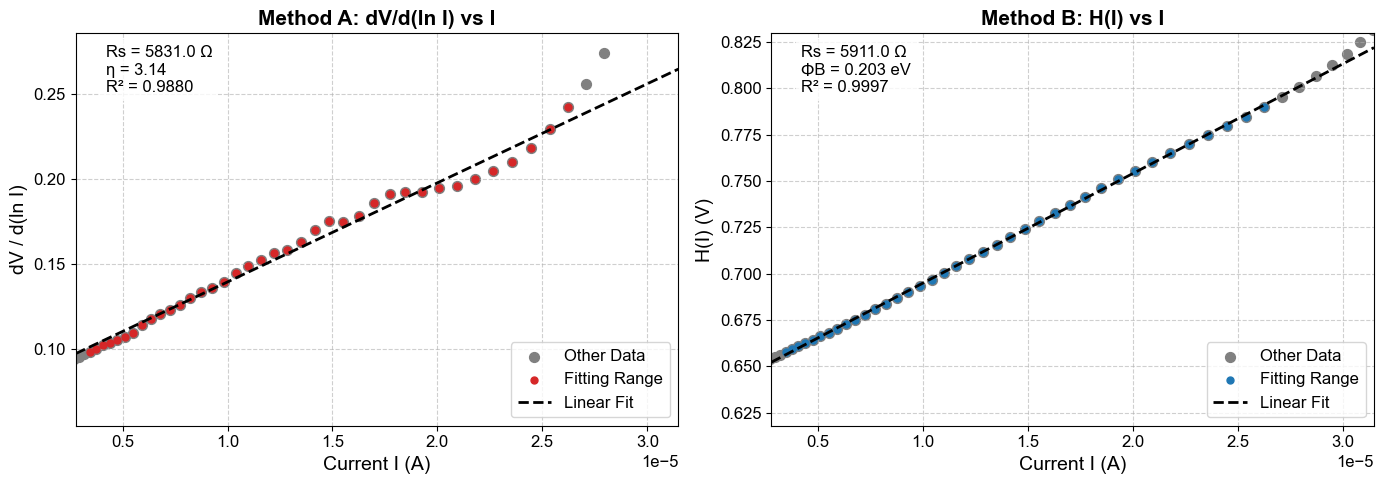

In [ ]:
# 執行分析

d_nm = 25
area_cm2 = np.pi * (d_nm/2 * 1e-7)**2

xs, ys = 75, 71
spectrum = h5map.get_spectrum_at_pixel(xs, ys)[3:] 
bias = h5map.bias_vector[3:]

res = cheung_analysis(bias, spectrum, area_cm2)

# --- 繪圖優化：聚焦於擬合區間 ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 設定 X 軸範圍 (緩衝區間：擬合範圍的 80% ~ 120%)
i_min, i_max = res['I'][res['mask']].min(), res['I'][res['mask']].max()
x_limit = (i_min * 0.8, i_max * 1.2)

# 準備標註文字
text_a = f"Rs = {res['Rs_a']:.1f} Ω\nη = {res['n_a']:.2f}\nR² = {res['r2_a']:.4f}"
text_b = f"Rs = {res['Rs_b']:.1f} Ω\nΦB = {res['phi_b']:.3f} eV\nR² = {res['r2_b']:.4f}"

# 執行局部繪圖
plot_focused_cheung(ax1, res['I'], res['y_a'], res['mask'], res['Rs_a'], 
                    res['n_a']*0.02585, 'Method A: dV/d(ln I) vs I', 'dV / d(ln I)', text_a)

plot_focused_cheung(ax2, res['I'], res['H_I'], res['mask'], res['Rs_b'], 
                    res['n_a'] * res['phi_b'], 'Method B: H(I) vs I', 'H(I) (V)', text_b)

plt.tight_layout()

from pathlib import Path

# 設定儲存路徑
save_dir = Path("analysis_results/schottky_plots")
save_dir.mkdir(parents=True, exist_ok=True) # 自動建立資料夾

file_name = f"point_{xs}_{ys}_cheung_method.png"
save_path = save_dir / file_name

plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"圖表已儲存至: {save_path}")

plt.show()

(-1.2, 1.2)

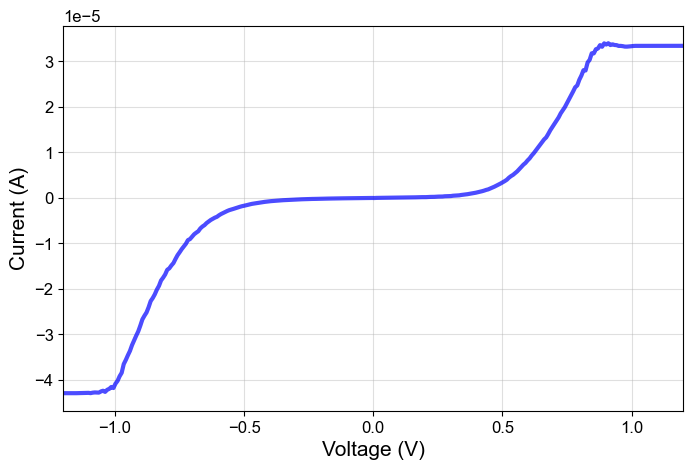

In [ ]:
fig, ax = plot_iv(bias, spectrum, False)
ax.set_xlim(-1.2, 1.2)

## Sliding Window

**Accelerating by Numba** [Optiional]


## 數學原理詳細說明
1. 線性回歸公式推導

## 為什麼使用滑動窗口？
I-V 曲線的三個區域：
```text
高偏壓區 ──────┬───────── 串聯電阻主導 (線性)
               │
               ├───────── 過渡區 (適合Cheung方法)
               │
低偏壓區 ──────┴───────── 熱離子發射主導 (指數)
```
滑動窗口幫助我們：

自動尋找線性區：在過渡區找到最線性的部分

避免主觀選擇：不依賴手動選擇擬合範圍

適應不同器件：自動適應不同品質的I-V曲線

實際例子
假設原始數據：

```text
I = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0] mA
dV/d(lnI) = [100, 150, 200, 250, 300, 350, 400, 450, 500, 550] Ω
window_size = 5
```
滑動過程：

```text
窗口1: I[0:5], y[0:5] → 計算擬合 → R²=0.95
窗口2: I[1:6], y[1:6] → 計算擬合 → R²=0.98 (更好!)
窗口3: I[2:7], y[2:7] → 計算擬合 → R²=0.97
...

選擇 R² 最高的窗口作為最佳擬合區域
```

算法優化細節
1. 向量化計算
使用 np.sum() 和 np.dot() 代替Python循環

Numba可以進一步加速這些向量操作

2. 提前終止條件
如果 denom == 0，跳過該窗口（無窮大斜率）

如果物理約束不滿足，不考慮該擬合

3. 內存效率
不存儲所有候選結果，只存儲最佳值

避免創建不必要的臨時數組

In [9]:
from numba import njit
import numpy as np

@njit(cache=True)
def _numba_sliding_window_core(current_I, current_Ya, V_T, window_size):
    """
    核心滑動窗口算法 - 尋找最佳線性擬合區域
    
    參數:
    ----------
    current_I : numpy array
        電流值陣列 (經過平滑處理)
    current_Ya : numpy array  
        對應的 dV/d(lnI) 值 (方法A的y值)
    V_T : float
        熱電壓 kT/q (約 0.02585 eV @ 300K)
    window_size : int
        滑動窗口的大小
    
    返回:
    ----------
    best_slope : float
        最佳擬合斜率 (對應 R_s)
    best_intercept : float
        最佳擬合截距 (對應 n*V_T)
    best_r2 : float
        最佳擬合的決定係數 R²
    best_start_idx : int
        最佳擬合區域的起始索引
    """
    n_pts = len(current_I)
    
    # 存儲多個候選結果
    candidates = []
    
    for i in range(n_pts - window_size):
        x = current_I[i : i + window_size]
        y = current_Ya[i : i + window_size]
        
        # 線性擬合
        n = window_size
        sum_x = np.sum(x)
        sum_y = np.sum(y)
        sum_xx = np.dot(x, x)
        sum_xy = np.dot(x, y)
        sum_yy = np.dot(y, y)
        
        denom = (n * sum_xx - sum_x**2)
        if denom == 0: 
            continue
            
        m = (n * sum_xy - sum_x * sum_y) / denom
        c = (sum_y - m * sum_x) / n
        
        # 計算 R²
        num_r = (n * sum_xy - sum_x * sum_y)
        den_r2 = (n * sum_xx - sum_x**2) * (n * sum_yy - sum_y**2)
        r2 = (num_r**2) / den_r2 if den_r2 > 0 else 0
        
        # 計算標準誤差
        y_pred = m * x + c
        residuals = y - y_pred
        mse = np.sum(residuals**2) / (n - 2) if n > 2 else 0
        
        # 計算 ideality factor
        n_tmp = c / V_T
        
        candidates.append({
            'r2': r2,
            'mse': mse,
            'slope': m,
            'intercept': c,
            'n_tmp': n_tmp,
            'start_idx': i
        })
    
    # 如果沒有候選結果
    if len(candidates) == 0:
        return 0.0, 0.0, -1.0, -1
    
    # 按多個標準排序（加權評分）
    best_score = -1.0
    best_idx = -1
    
    for j, cand in enumerate(candidates):
        # 綜合評分：R² 為主，MSE 為輔
        score = cand['r2'] * 0.8 + (1.0 / (1.0 + cand['mse'])) * 0.2 if cand['mse'] > 0 else cand['r2']
        
        # 物理約束：斜率正、ideality factor 合理
        if cand['slope'] > 0 and 1.0 < cand['n_tmp'] < 10.0:
            if score > best_score:
                best_score = score
                best_idx = j
    
    if best_idx == -1:
        return 0.0, 0.0, -1.0, -1
    
    best = candidates[best_idx]
    return best['slope'], best['intercept'], best['r2'], best['start_idx']
    

ImportError: Numba needs NumPy 2.3 or less. Got NumPy 2.4.

In [ ]:
def advanced_cheung_analysis(bias, current, area_cm2, T=300, a_star=54.0, 
                           window_fraction=0.15, min_r2=0.95):
    """
    cheung analysis with sliding window
    
    """
    
    try:
        # 基本物理常數
        V_T = 8.617333e-5 * T
        constant_term = area_cm2 * a_star * (T**2)
        
        # 1. 輸入數據預處理和驗證
        bias = np.asarray(bias, dtype=np.float64)
        current = np.asarray(current, dtype=np.float64)
        
        # 檢查數據長度
        assert len(bias) == len(current), "bias and current must have same length"
        
        # 2. 數據平滑處理
        abs_I = np.abs(current)
        
        # 使用滾動中值去除尖峰
        pad_size = 7 // 2
        padded_I = np.pad(abs_I, pad_size, mode='edge')
        
        # 使用滑動窗口視圖計算中值
        sliding_view = np.lib.stride_tricks.sliding_window_view(padded_I, 7)
        I_median = np.median(sliding_view, axis=-1)
        
        # Savitzky-Golay 濾波
        window_length = min(31, len(I_median))
        if window_length % 2 == 0:  # 確保奇數
            window_length -= 1
        if window_length >= 5:  # 最小窗口大小
            from scipy.signal import savgol_filter
            I_smooth = savgol_filter(I_median, window_length=window_length, polyorder=3)
        else:
            I_smooth = I_median.copy()
        
        # 3. 計算 dV/d(lnI)
        # 避免 log(0) 或負值
        I_smooth_clipped = np.maximum(I_smooth, 1e-20)
        ln_I = np.log(I_smooth_clipped)
        
        # 計算導數，增加穩定性
        try:
            y_func_a = np.gradient(bias) / np.gradient(ln_I)
        except:
            # 如果導數計算失敗，使用差分近似
            dy = np.diff(bias) / np.diff(ln_I)
            y_func_a = np.zeros_like(bias)
            y_func_a[:-1] = dy
            y_func_a[-1] = dy[-1]
        
        # 4. 確定搜索區域
        noise_floor = np.max(I_smooth) * 0.01
        search_mask = (bias > 0.2) & (I_smooth > noise_floor)
        indices = np.where(search_mask)[0]
        
        if len(indices) < 20:  # 增加最小數據點要求
            return create_empty_res(bias, y_func_a, I_smooth, 
                                  error=f"Not enough data points in search region: {len(indices)}")
        
        # 5. 計算窗口大小，增加合理性檢查
        base_window = max(15, int(len(indices) * window_fraction))  # 最小15個點
        base_window = min(base_window, len(indices) - 5)  # 不能超過數據點數減5
        
        # 創建窗口大小候選列表
        window_candidates = []
        factors = [0.25, 0.5, 0.75, 1.0, 1.25, 1.5]
        
        for factor in factors:
            ws = int(base_window * factor)
            if 15 <= ws <= len(indices) - 10:  # 確保足夠的移動空間
                window_candidates.append(ws)
        
        # 去重並排序
        window_candidates = sorted(set(window_candidates))
        
        if not window_candidates:
            return create_empty_res(bias, y_func_a, I_smooth,
                                  error="No valid window sizes found")
        
        best_results = {
            'r2': -1.0,
            'window_size': 0,
            'm_a': 0.0,
            'c_a': 0.0,
            'start_idx': -1
        }
        
        # 6. 對每個窗口大小進行搜索
        for ws in window_candidates:
            try:
                m_a, c_a, r2, start_off = _numba_sliding_window_core(
                    I_smooth[indices], y_func_a[indices], V_T, ws
                )
                
                # 確保返回值是有效的
                if start_off == -1:
                    continue
                    
                start_off = int(start_off)
                
                # 計算 ideality factor
                n_tmp = c_a / V_T
                
                # 檢查結果質量 - 增加更多檢查
                is_valid = (
                    r2 > min_r2 and 
                    m_a > 0 and 
                    0.8 < n_tmp < 15.0 and  # 放寬理想因子範圍
                    start_off >= 0 and
                    start_off + ws <= len(indices) and
                    m_a < 1e6  # 避免過大的電阻值
                )
                
                # 如果找到更好的結果，更新
                if is_valid and r2 > best_results['r2']:
                    best_results.update({
                        'r2': float(r2),
                        'window_size': int(ws),
                        'm_a': float(m_a),
                        'c_a': float(c_a),
                        'start_idx': int(start_off)
                    })
                    
            except Exception as e:
                # 跳過該窗口大小的錯誤
                continue
        
        # 7. 檢查是否找到有效結果
        if best_results['r2'] < min_r2 or best_results['start_idx'] == -1:
            error_msg = f"No valid fit found (best R²={best_results['r2']:.3f}, tried windows: {window_candidates})"
            return create_empty_res(bias, y_func_a, I_smooth, error=error_msg)
        
        # 8. 計算結果參數
        n_a = best_results['c_a'] / V_T
        Rs_a = best_results['m_a']
        ws = int(best_results['window_size'])
        start_off = int(best_results['start_idx'])
        
        # 檢查索引範圍是否有效
        if start_off < 0 or start_off + ws > len(indices):
            return create_empty_res(bias, y_func_a, I_smooth, error="Invalid index range")
        
        # 找到對應的索引範圍
        idx_fit = indices[start_off : start_off + ws]
        
        # 確保索引是整數陣列
        idx_fit = np.array(idx_fit, dtype=int)
        
        # 9. 計算 H(I) 和方法 B 參數
        # 數值穩定性處理
        log_arg = I_smooth / constant_term
        log_arg = np.maximum(log_arg, 1e-15)
        
        try:
            H_I = bias - (n_a * V_T * np.log(log_arg))
        except:
            # 如果計算失敗，返回空結果
            return create_empty_res(bias, y_func_a, I_smooth, error="H(I) calculation failed")
        
        # 方法 B 的線性擬合
        try:
            from scipy import stats
            slope_b, intercept_b, r_val_b, _, _ = stats.linregress(
                I_smooth[idx_fit], H_I[idx_fit]
            )
            phi_b = intercept_b / n_a
            r2_b = r_val_b**2
        except:
            # 如果擬合失敗，使用默認值
            slope_b = np.nan
            phi_b = np.nan
            r2_b = 0.0
        
        # 10. 返回完整結果
        return {
            'n': float(n_a),
            'Rs_a': float(Rs_a),
            'phi_b': float(phi_b),
            'Rs_b': float(slope_b),
            'r2_a': float(best_results['r2']),
            'r2_b': float(r2_b),
            'fit_range': (float(bias[idx_fit[0]]), float(bias[idx_fit[-1]])),
            'indices': idx_fit,
            'window_size': ws,
            'H_I': H_I,
            'y_a': y_func_a,
            'I_smooth': I_smooth,
            'bias': bias,
            'current': current,
            'success': True,
            'method': f"Multi-window search (ws={ws}, fraction={window_fraction})",
            'fit_region_size': ws,
            'fit_quality': 'good' if best_results['r2'] > 0.98 else 'acceptable',
            'window_candidates': window_candidates,
            'window_fraction_used': window_fraction
        }
        
    except Exception as e:
        # 捕獲所有其他錯誤
        error_msg = f"Analysis failed with error: {str(e)}"
        print(f"Error in advanced_cheung_analysis: {e}")
        
        # 嘗試返回一個基本的空結果
        try:
            return create_empty_res(bias, np.zeros_like(bias), np.zeros_like(bias), error=error_msg)
        except:
            # 如果連空結果都無法創建，返回最小的字典
            return {
                'success': False,
                'error': error_msg,
                'n': np.nan,
                'phi_b': np.nan,
                'Rs_a': np.nan,
                'r2_a': 0.0
            }

def create_empty_res(bias, y_func_a, I_smooth, error="Unknown error"):
    """創建空的結果字典"""
    return {
        'n': np.nan, 
        'Rs_a': np.nan, 
        'phi_b': np.nan, 
        'Rs_b': np.nan,
        'r2_a': 0.0, 
        'r2_b': 0.0,
        'fit_range': (np.nan, np.nan),
        'indices': np.array([], dtype=int),
        'window_size': 0,
        'H_I': np.full_like(bias, np.nan),
        'y_a': y_func_a,
        'I_smooth': I_smooth,
        'bias': bias,
        'current': np.full_like(bias, np.nan),
        'success': False,
        'method': 'No fit found',
        'fit_region_size': 0,
        'fit_quality': 'poor',
        'error': error
    }

In [12]:
def test_window_fractions(bias, current, area_cm2, fractions=[0.1, 0.15, 0.2, 0.25, 0.3]):
    """
    測試不同 window_fraction 參數的效果
    """
    results = {}
    
    print("Testing different window fractions...")
    print("-" * 60)
    
    for fraction in fractions:
        print(f"\nTesting window_fraction = {fraction}")
        
        try:
            result = advanced_cheung_analysis(
                bias, current, area_cm2, 
                window_fraction=fraction
            )
            
            results[fraction] = result
            
            if result['success']:
                print(f"  Success: Yes")
                print(f"  n = {result['n']:.3f}")
                print(f"  Φ_b = {result['phi_b']:.3f} eV")
                print(f"  R² = {result['r2_a']:.4f}")
                print(f"  Window size used: {result['window_size']}")
                print(f"  Fit range: {result['fit_range'][0]:.3f}-{result['fit_range'][1]:.3f} V")
            else:
                print(f"  Success: No")
                print(f"  Error: {result.get('error', 'Unknown')}")
                
        except Exception as e:
            print(f"  Error during analysis: {e}")
            results[fraction] = {'success': False, 'error': str(e)}
    
    # 繪製比較圖
    successful_results = {k: v for k, v in results.items() if v['success']}
    
    if successful_results:
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        
        fractions_list = list(successful_results.keys())
        
        # 1. n 值比較
        n_values = [successful_results[f]['n'] for f in fractions_list]
        axes[0, 0].plot(fractions_list, n_values, 'bo-', markersize=8)
        axes[0, 0].set_xlabel('Window Fraction')
        axes[0, 0].set_ylabel('Ideality Factor (n)')
        axes[0, 0].set_title('n vs Window Fraction')
        axes[0, 0].grid(True, alpha=0.3)
        
        # 2. Φ_b 比較
        phi_values = [successful_results[f]['phi_b'] for f in fractions_list]
        axes[0, 1].plot(fractions_list, phi_values, 'ro-', markersize=8)
        axes[0, 1].set_xlabel('Window Fraction')
        axes[0, 1].set_ylabel('SBH (Φ_b) (eV)')
        axes[0, 1].set_title('Φ_b vs Window Fraction')
        axes[0, 1].grid(True, alpha=0.3)
        
        # 3. R² 比較
        r2_values = [successful_results[f]['r2_a'] for f in fractions_list]
        axes[0, 2].plot(fractions_list, r2_values, 'go-', markersize=8)
        axes[0, 2].set_xlabel('Window Fraction')
        axes[0, 2].set_ylabel('R²')
        axes[0, 2].set_title('R² vs Window Fraction')
        axes[0, 2].grid(True, alpha=0.3)
        
        # 4. 窗口大小比較
        window_sizes = [successful_results[f]['window_size'] for f in fractions_list]
        axes[1, 0].plot(fractions_list, window_sizes, 'mo-', markersize=8)
        axes[1, 0].set_xlabel('Window Fraction')
        axes[1, 0].set_ylabel('Window Size (points)')
        axes[1, 0].set_title('Window Size vs Fraction')
        axes[1, 0].grid(True, alpha=0.3)
        
        # 5. 擬合範圍寬度
        fit_widths = [successful_results[f]['fit_range'][1] - successful_results[f]['fit_range'][0] 
                     for f in fractions_list]
        axes[1, 1].plot(fractions_list, fit_widths, 'co-', markersize=8)
        axes[1, 1].set_xlabel('Window Fraction')
        axes[1, 1].set_ylabel('Fit Width (V)')
        axes[1, 1].set_title('Fit Range Width vs Fraction')
        axes[1, 1].grid(True, alpha=0.3)
        
        # 6. 成功率統計
        axes[1, 2].axis('off')
        summary_text = "PARAMETER SENSITIVITY ANALYSIS\n"
        summary_text += "="*40 + "\n\n"
        
        for i, fraction in enumerate(fractions_list):
            summary_text += f"Fraction {fraction}:\n"
            summary_text += f"  n = {n_values[i]:.3f}\n"
            summary_text += f"  Φ_b = {phi_values[i]:.3f} eV\n"
            summary_text += f"  R² = {r2_values[i]:.4f}\n"
            summary_text += f"  Window = {window_sizes[i]} pts\n"
            summary_text += f"  Width = {fit_widths[i]:.3f} V\n\n"
        
        axes[1, 2].text(0.1, 0.95, summary_text, 
                       fontfamily='monospace', fontsize=9,
                       verticalalignment='top',
                       bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
        
        plt.tight_layout()
        plt.show()
    
    return results

Testing different window fractions...
------------------------------------------------------------

Testing window_fraction = 0.1
  Success: Yes
  n = 5.652
  Φ_b = 0.066 eV
  R² = 0.9752
  Window size used: 16
  Fit range: 0.253-0.373 V

Testing window_fraction = 0.15
  Success: Yes
  n = 5.652
  Φ_b = 0.066 eV
  R² = 0.9752
  Window size used: 16
  Fit range: 0.253-0.373 V

Testing window_fraction = 0.2
  Success: No
  Error: No valid fit found (best R²=-1.000, tried windows: [22, 33, 45, 56, 67])

Testing window_fraction = 0.25
  Success: No
  Error: No valid fit found (best R²=-1.000, tried windows: [28, 42, 56, 70, 84])

Testing window_fraction = 0.3
  Success: Yes
  n = 5.652
  Φ_b = 0.066 eV
  R² = 0.9752
  Window size used: 16
  Fit range: 0.253-0.373 V


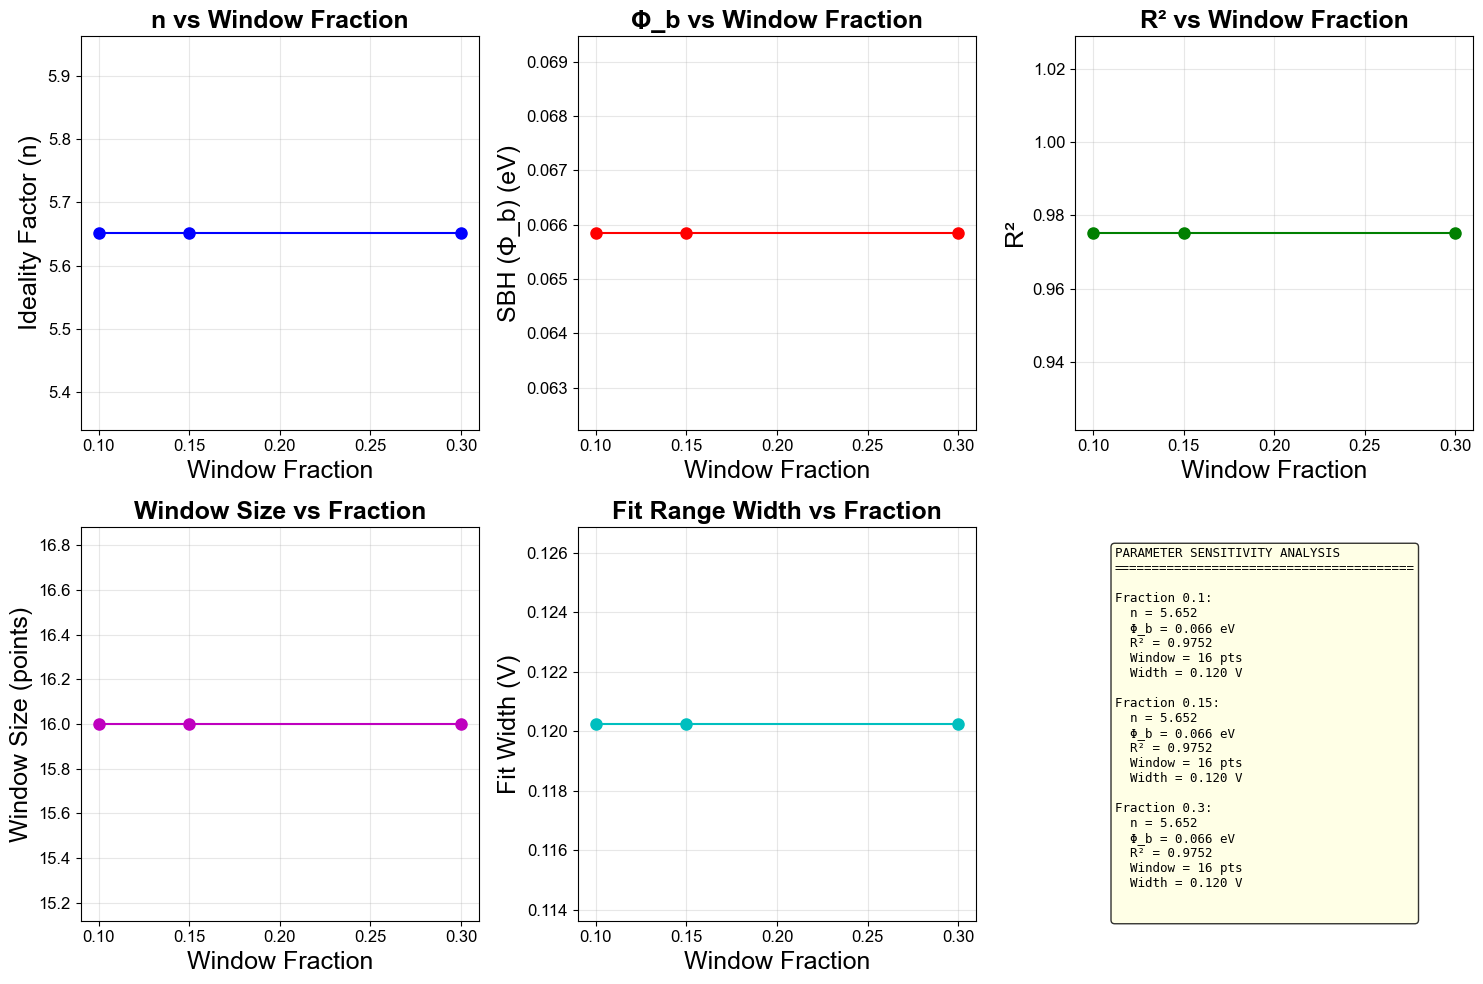


Best window_fraction: 0.1 (R² = 0.9752)


NameError: name 'plot_cheung_results' is not defined

In [14]:
# 測試不同 window_fraction
xs, ys = 21, 65
spectrum = h5map.get_spectrum_at_pixel(xs, ys)[3:] 
bias = h5map.bias_vector[3:]

# 正確計算面積
d_nm = 25  # 直徑 25 nm
d_cm = d_nm * 1e-7  # 轉換為 cm
radius_cm = d_cm / 2
area_cm2 = np.pi * (radius_cm ** 2)

# 測試多個 fraction 值
test_results = test_window_fractions(bias, spectrum, area_cm2, 
                                    fractions=[0.1, 0.15, 0.2, 0.25, 0.3])

# 使用最佳 fraction
# 自動選擇 R² 最高的 fraction
best_fraction = None
best_r2 = -1

for fraction, result in test_results.items():
    if result['success'] and result['r2_a'] > best_r2:
        best_r2 = result['r2_a']
        best_fraction = fraction

if best_fraction is not None:
    print(f"\nBest window_fraction: {best_fraction} (R² = {best_r2:.4f})")
    
    # 使用最佳參數重新分析
    result = advanced_cheung_analysis(
        bias, spectrum, area_cm2, 
        window_fraction=best_fraction
    )
    
    # 繪製和保存
    fig = plot_cheung_results(bias, spectrum, result)
    
    if result['success']:
        # 保存到 schottky-cheung 目錄
        import os
        output_dir = 'schottky-cheung'
        if not os.path.exists(output_dir):
            os.makedirs(output_dir)
        
        filename = f'cheung_analysis_pixel_{xs}_{ys}_fraction{best_fraction}.png'
        filepath = os.path.join(output_dir, filename)
        
        fig.savefig(filepath, dpi=300, bbox_inches='tight')
        print(f"圖表已保存為 '{filepath}'")
        
        # 顯示 HTML 表格
        display_html_table(result)
    else:
        print(f"分析失敗: {result.get('error', 'Unknown error')}")
else:
    print("沒有找到成功的分析結果")

In [17]:
import matplotlib.pyplot as plt
import numpy as np

def plot_cheung_results_with_deviation(bias, current, res, pixel_coord=(0,0)):
    if res is None or len(res['indices']) == 0:
        print(f"Skipping plot for {pixel_coord}: No valid fit indices.")
        return # 直接結束，避免執行後面的 np.min()

    # 1. 準備數據
    I = np.abs(current)
    y_a = res['y_a']
    H_I = res['H_I']
    v_start, v_end = res['fit_range']
    fit_indices = res['indices']
    
    # 建立畫布
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    plt.subplots_adjust(wspace=0.3, bottom=0.15)
    fig.suptitle(fr"Cheung Method Analysis at Pixel {pixel_coord}", fontsize=17, y=1.02)

    # --- Plot 1: Semi-log I-V ---
    ax0 = axes[0, 0]
    ax0.semilogy(bias, I, color='gray', lw = 3, alpha=0.6, label='Full Data')
    ax0.semilogy(bias[fit_indices], I[fit_indices], 'r.', label='Fitting Range')
    ax0.axvspan(v_start, v_end, color='green', alpha=0.1)
    ax0.set_xlabel('Voltage (V)', fontsize = 15)
    ax0.set_ylabel('Current (A)', fontsize = 15)
    ax0.set_title('I-V Characteristic (logy)', fontsize = 15)
    ax0.grid(True, linestyle='-', alpha=0.4)
    ax0.legend(fontsize = 11)

    # --- Plot 2 normal I-V
    ax1 = axes[0, 1]
    ax1.plot(bias, I, color='gray', lw = 3, alpha=0.6, label='Full Data')
    ax1.plot(bias[fit_indices], I[fit_indices], 'r.', label='Fitting Range')
    ax1.axvspan(v_start, v_end, color='green', alpha=0.1)
    ax1.set_xlabel('Voltage (V)', fontsize = 15)
    ax1.set_ylabel('Current (A)', fontsize = 15)
    ax1.set_title('I-V Characteristic', fontsize = 15)
    ax1.grid(True, linestyle='-', alpha=0.4)
    ax1.legend(fontsize = 11)

    # --- Plot 2: Method A (dV/dlnI vs I) ---
    ax2 = axes[1, 0]
    # 畫出全部點，看整體的彎曲趨勢
    ax2.scatter(I, y_a, c='gray', s=20, alpha=0.2, label='Outside Range')
    # 畫出擬合點
    ax2.scatter(I[fit_indices], y_a[fit_indices], c='red', s=30, label='Fit Range')
    
    # 繪製擬合線 (延伸一點點以便觀察)
    I_range = I[fit_indices]
    I_ext = np.linspace(np.min(I_range)*0.5, np.max(I_range)*1.2, 100)
    V_T = 8.617333e-5 * 300 # 假設 T=300K
    intercept_a = res['n'] * V_T
    ax2.plot(I_ext, res['Rs_a'] * I_ext + intercept_a, 'k--', alpha=0.8)
    
    ax2.set_xlabel('Current I (A)', fontsize = 15)
    ax2.set_ylabel('dV / d(ln I)', fontsize = 15)
    ax2.set_title(r'Method A: $dV/d(\ln I) = nV_T + IR_s$', fontsize = 15)
    
    text_a = fr"Rs = {res['Rs_a']:.1f} $\Omega$" + "\n" + fr"$n$ = {res['n']:.2f}" + "\n" + fr"$R^2$ = {res['r2_a']:.4f}"
    ax2.text(0.05, 0.95, text_a, transform=ax2.transAxes, verticalalignment='top',
             fontsize = 12,
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    # --- Plot 3: Method B (H(I) vs I) ---
    ax3 = axes[1, 1]
    # 畫出全部點
    ax3.scatter(I, H_I, c='gray', s=20, alpha=0.4, label='Outside Range')
    # 畫出擬合點
    ax3.scatter(I[fit_indices], H_I[fit_indices], c='blue', s=30, label='Fit Range')
    
    # 繪製擬合線
    intercept_b = res['phi_b'] * res['n']
    ax3.plot(I_ext, res['Rs_b'] * I_ext + intercept_b, 'k--', alpha=0.8)
    
    ax3.set_xlabel('Current I (A)',fontsize = 15)
    ax3.set_ylabel('H(I)', fontsize = 15)
    ax3.set_title(r'Method B: $H(I) = n\Phi_b + IR_s$',fontsize = 15)
    
    text_b = fr"Rs = {res['Rs_b']:.1f} $\Omega$" + "\n" + fr"$\Phi_b$ = {res['phi_b']:.3f} eV" + "\n" + fr"$R^2$ = {res['r2_b']:.4f}"
    ax3.text(0.05, 0.95, text_b, transform=ax3.transAxes, verticalalignment='top',
             fontsize = 12,
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    for ax, y_data in zip([ax2, ax3], [y_a, H_I]): # 直接配對 ax 與對應的數據
        ax.legend(loc='lower right', fontsize=11)
        ax.grid(True, linestyle='-', alpha=0.4)
        
        # X 軸：以擬合範圍為主
        current_I_fit = I[fit_indices]
        ax.set_xlim(0, np.max(current_I_fit) * 1.4)
        
        # Y 軸：根據該 ax 專屬的擬合數據來決定範圍
        y_fit_vals = y_data[fit_indices]
        y_min, y_max = np.min(y_fit_vals), np.max(y_fit_vals)
        y_range = y_max - y_min
        
        # 給予上下 20% 的緩衝空間，避免數據貼邊
        ax.set_ylim(y_min - 0.2 * y_range, y_max + 0.2 * y_range)

    plt.tight_layout()
    
    from pathlib import Path

    # 設定儲存路徑
    save_dir = Path("analysis_results/schottky_plots")
    save_dir.mkdir(parents=True, exist_ok=True) # 自動建立資料夾
    
    # 檔名包含座標，方便溯源
    file_name = f"point_{pixel_coord}_cheung_sliding_window_fit.png"
    save_path = save_dir / file_name

    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"圖表已儲存至: {save_path}")
    
    plt.show()

In [19]:
#d_nm = 25
#area_cm2 = np.pi * (d_nm/2 * 1e-7)**2

xs, ys = 35, 32
spectrum = h5map.get_spectrum_at_pixel(xs, ys)[3:] 
bias = h5map.bias_vector[3:]

res = advanced_cheung_analysis(bias, spectrum, area_cm2)
plot_cheung_results_with_deviation(bias, spectrum, res, pixel_coord=(xs, ys))

Skipping plot for (35, 32): No valid fit indices.


In [70]:
def plot_cheung_results(bias, current, result, figsize=(12, 8)):
    """
    繪製 Cheung 分析結果的完整圖表
    - Method A: subplot(2,3,4)
    - Method B: subplot(2,3,5)
    """

    # 檢查結果是否有效
    if not result.get('success', False):
        print(f"無法繪製：分析失敗 - {result.get('error', 'Unknown error')}")
        
        # 創建簡單的錯誤圖
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # 原始 I-V 曲線
        axes[0].plot(bias, current * 1e6, 'b-')
        axes[0].set_xlabel('Bias Voltage (V)')
        axes[0].set_ylabel('Current (µA)')
        axes[0].set_title('Original I-V Curve')
        axes[0].grid(True, alpha=0.3)
        
        # 錯誤信息
        axes[1].axis('off')
        error_text = f"ANALYSIS FAILED\n"
        error_text += "="*40 + "\n\n"
        error_text += f"Error: {result.get('error', 'Unknown')}\n\n"
        error_text += f"Data Points: {len(bias)}\n"
        error_text += f"Bias Range: {bias[0]:.3f} to {bias[-1]:.3f} V\n"
        error_text += f"Current Range: {current.min():.2e} to {current.max():.2e} A"
        
        axes[1].text(0.1, 0.5, error_text, 
                    fontfamily='monospace', fontsize=10,
                    verticalalignment='center',
                    bbox=dict(boxstyle='round', facecolor='lightcoral', alpha=0.8))
        
        plt.tight_layout()
        return fig
        
    if not result['success']:
        print("無法繪製：分析失敗")
        return None
    
    fig = plt.figure(figsize=figsize)
    
    # 1. 原始 I-V 曲線（線性座標）
    ax1 = plt.subplot(2, 2, 1)
    ax1.plot(bias, current * 1e6, 'bo', markersize = 3, alpha=0.6, label='Original')
    ax1.plot(bias, result['I_smooth'] * 1e6, 'ro', markersize = 3, alpha=0.6, label='Smoothed')
    
    # 標記擬合區域
    if len(result['indices']) > 0:
        fit_bias = bias[result['indices']]
        fit_current = current[result['indices']]
        
        # 添加擬合區域陰影
        fit_min, fit_max = result['fit_range']
        ax1.axvspan(fit_min, fit_max, alpha=0.2, color='green', label=f'Fit range: {fit_min:.3f}-{fit_max:.3f} V')
    
    ax1.axhline(y=0, color='k', linestyle='-', linewidth=0.5, alpha=0.3)
    ax1.axvline(x=0, color='k', linestyle='-', linewidth=0.5, alpha=0.3)
    ax1.set_xlabel('Bias Voltage (V)', fontsize=12)
    ax1.set_ylabel('Current (µA)', fontsize=12)
    ax1.set_title('I-V Characteristic', fontsize=14, fontweight='bold')
    ax1.legend(loc='best')
    ax1.grid(True, alpha=0.3)
    
    # 2. 原始 I-V 曲線（半對數座標）
    ax2 = plt.subplot(2, 2, 2)
    pos_mask = bias > 0
    neg_mask = bias < 0
    
    if np.any(pos_mask):
        ax2.semilogy(bias[pos_mask], np.abs(current[pos_mask]) * 1e6, 'b-', 
                    linewidth=1.5, label='Forward')
    if np.any(neg_mask):
        ax2.semilogy(-bias[neg_mask], np.abs(current[neg_mask]) * 1e6, 'r-', 
                    linewidth=1.5, label='Reverse')
    
    # 添加擬合區域陰影
        fit_min, fit_max = result['fit_range']
        ax2.axvspan(fit_min, fit_max, alpha=0.2, color='green', label=f'Fit range: {fit_min:.3f}-{fit_max:.3f} V')
    
    ax2.set_xlabel('|Bias Voltage| (V)', fontsize=12)
    ax2.set_ylabel('|Current| (µA)', fontsize=12)
    ax2.set_title('Semi-log I-V Plot', fontsize=14, fontweight='bold')
    ax2.legend(loc='best')
    ax2.grid(True, alpha=0.3, which='both')
    
    
    # 4. 方法 A: dV/d(lnI) vs I (位置 4)
    ax3 = plt.subplot(2, 2, 3)
    
    # 獲取擬合區域的索引
    if len(result['indices']) > 0:
        idx_fit = result['indices']
        
        # 計算擬合區域前後 x% 的數據點
        n_total = len(bias)
        margin = int(0.018 * n_total)  # 2.% 的數據點
        
        # 創建擴展的顯示區域
        start_extended = max(0, idx_fit[0] - margin)
        end_extended = min(n_total, idx_fit[-1] + margin)
        idx_extended = np.arange(start_extended, end_extended)
        
        # 繪製擴展區域的數據（灰色）
        ax3.plot(bias[idx_extended], result['y_a'][idx_extended], 
                'o', color='gray', linewidth=1, alpha=0.5, label='Data')
        
        # 繪製擬合區域的數據（藍色）
        ax3.plot(bias[idx_fit], result['y_a'][idx_fit], 'bo', 
                markersize=6, label='Fit points')
        
        # 繪製擬合線（紅色）
        I_fit = result['I_smooth'][idx_fit]
        y_fit = result['Rs_a'] * I_fit + result['n'] * 8.617e-5 * 300  # n*V_T
        
        ax3.plot(bias[idx_fit], y_fit, 'r-', linewidth=2, 
                label=f'Linear fit (R²={result["r2_a"]:.4f})')
        
        # 添加擬合方程式
        fit_eq = f'y = {result["Rs_a"]:.1f}·I + {result["n"]*8.617e-5*300:.3f}'
        ax3.text(0.05, 0.95, fit_eq, transform=ax3.transAxes,
                fontsize=11, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    ax3.set_xlabel('Bias Voltage (V)', fontsize=12)
    ax3.set_ylabel('dV/d(lnI) (V)', fontsize=12)
    ax3.set_title(f'Cheung Method A\nn = {result["n"]:.3f}, Rs = {result["Rs_a"]:.1f} Ω', 
                 fontsize=12, fontweight='bold')
    ax3.legend(loc='best', fontsize=11)
    ax3.grid(True, alpha=0.3)
    
    # 5. 方法 B: H(I) vs I 
    ax4 = plt.subplot(2, 2, 4)
    
    if len(result['indices']) > 0:
        idx_fit = result['indices']
        I_abs = np.abs(result['I_smooth'])
        H_I = result['H_I']
        
        # 計算擴展顯示區域
        start_extended = max(0, idx_fit[0] - margin)
        end_extended = min(n_total, idx_fit[-1] + margin)
        idx_extended = np.arange(start_extended, end_extended)
        
        # 繪製擴展區域的數據（灰色）
        ax4.plot(I_abs[idx_extended] * 1e6, H_I[idx_extended], 
                'o', color='gray', linewidth=1, alpha=0.5, label='Data')
        
        # 繪製擬合區域的數據（藍色）
        ax4.plot(I_abs[idx_fit] * 1e6, H_I[idx_fit], 'bo', 
                markersize=6, label='Fit points')
        
        # 繪製擬合線（紅色）
        I_fit_abs = np.abs(I_fit)
        H_fit = result['Rs_b'] * I_fit + result['n'] * result['phi_b']
        
        ax4.plot(I_fit_abs * 1e6, H_fit, 'r-', linewidth=2,
                label=f'Linear fit (R²={result["r2_b"]:.4f})')
        
        # 添加擬合方程式
        fit_eq = f'H = {result["Rs_b"]:.1f}·I + {result["n"]*result["phi_b"]:.3f}'
        ax4.text(0.05, 0.95, fit_eq, transform=ax4.transAxes,
                fontsize=11, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    ax4.set_xlabel('Current (µA)', fontsize=12)
    ax4.set_ylabel('H(I) (V)', fontsize=12)
    ax4.set_title(f'Cheung Method B\n' + fr'$\Phi_b$ = {result["phi_b"]:.3f} eV, $R_s$ = {result["Rs_b"]:.1f} $\Omega$', 
             fontsize=12, fontweight='bold')
    ax4.legend(loc='best', fontsize=11)
    ax4.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    # 添加整體標題
    fig.suptitle(f'Schottky Barrier Analysis - Pixel ({xs}, {ys})', 
                fontsize=16, fontweight='bold', y=1.02)
    
    return fig


In [28]:
from IPython.display import display, HTML

def display_html_table(result):
    """在Jupyter中顯示HTML表格"""
    
    html = """
    <style>
    .cheung-table {
        border-collapse: collapse;
        margin: 10px 0;
        font-family: Arial, sans-serif;
        min-width: 400px;
        box-shadow: 0 0 10px rgba(0, 0, 0, 0.1);
    }
    .cheung-table thead tr {
        background-color: #4a6fa5;
        color: #ffffff;
        text-align: left;
        font-weight: bold;
    }
    .cheung-table th,
    .cheung-table td {
        padding: 12px 15px;
    }
    .cheung-table tbody tr {
        border-bottom: 1px solid #dddddd;
    }
    .cheung-table tbody tr:nth-of-type(even) {
        background-color: #f3f3f3;
    }
    .cheung-table tbody tr:last-of-type {
        border-bottom: 2px solid #4a6fa5;
    }
    .cheung-table tbody tr:hover {
        background-color: #e8f4f8;
    }
    .good-fit { color: green; font-weight: bold; }
    .fair-fit { color: orange; font-weight: bold; }
    .poor-fit { color: red; font-weight: bold; }
    </style>
    
    <table class="cheung-table">
        <thead>
            <tr>
                <th>Parameter</th>
                <th>Value</th>
                <th>Unit</th>
            </tr>
        </thead>
        <tbody>
    """
    
    # 添加數據行
    rows = [
        ("Ideality Factor (n)", f"{result['n']:.3f}", ""),
        ("Schottky Barrier (Φ_b)", f"{result['phi_b']:.3f}", "eV"),
        ("Series Resistance (A)", f"{result['Rs_a']:.1f}", "Ω"),
        ("Series Resistance (B)", f"{result['Rs_b']:.1f}", "Ω"),
        ("R² (Method A)", f"{result['r2_a']:.4f}", ""),
        ("R² (Method B)", f"{result['r2_b']:.4f}", ""),
        ("Fit Range", f"{result['fit_range'][0]:.3f}-{result['fit_range'][1]:.3f}", "V"),
        ("Fit Quality", result['fit_quality'].upper(), ""),
        ("Window Size", str(result['window_size']), "points"),
        ("Data Points", str(len(result['bias'])), "")
    ]
    
    for param, value, unit in rows:
        html += f"""
            <tr>
                <td>{param}</td>
                <td>{value}</td>
                <td>{unit}</td>
            </tr>
        """
    
    html += """
        </tbody>
    </table>
    
    <div style="margin-top: 20px; padding: 10px; background-color: #f8f9fa; border-radius: 5px;">
        <h4>Analysis Summary</h4>
        <p>Temperature: 300 K | Contact Area: """ + f"{np.pi*(12.5e-7)**2:.2e} cm²" + """</p>
        <p>Analysis Method: """ + result['method'] + """</p>
    </div>
    """
    
    display(HTML(html))


### Save results

In [47]:
import os
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime

def setup_output_directory(base_dir='schottky-cheung', create_subdir=True):
    """
    設置輸出目錄結構
    
    參數:
    ----------
    base_dir : str
        基礎目錄名稱
    create_subdir : bool
        是否創建帶時間戳的子目錄
        
    返回:
    ----------
    output_dir : str
        完整的輸出目錄路徑
    """
    # 確保基礎目錄存在
    if not os.path.exists(base_dir):
        os.makedirs(base_dir)
        print(f"Created directory: {base_dir}")
    
    if create_subdir:
        # 創建帶時間戳的子目錄
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        output_dir = os.path.join(base_dir, f"analysis_{timestamp}")
    else:
        output_dir = base_dir
    
    # 創建輸出目錄
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
        print(f"Created output directory: {output_dir}")
    
    # 在目錄中創建子目錄結構
    subdirs = ['figures', 'data', 'logs', 'reports']
    for subdir in subdirs:
        subdir_path = os.path.join(output_dir, subdir)
        if not os.path.exists(subdir_path):
            os.makedirs(subdir_path)
            print(f"Created subdirectory: {subdir_path}")
    
    return output_dir

In [51]:
def save_single_pixel_analysis(bias, current, result, xs, ys, output_dir='schottky-cheung'):
    """
    保存單個像素點的 Cheung 分析結果
    
    參數:
    ----------
    bias : array
        偏壓陣列
    current : array
        電流陣列
    result : dict
        分析結果
    xs, ys : int
        像素座標
    output_dir : str
        輸出目錄
        
    返回:
    ----------
    saved_paths : dict
        保存的文件路徑
    """
    # 設置輸出目錄
    output_dir = setup_output_directory(output_dir, create_subdir=False)
    
    # 創建像素點專用子目錄
    pixel_dir = os.path.join(output_dir, 'figures', f'pixel_{xs}_{ys}')
    if not os.path.exists(pixel_dir):
        os.makedirs(pixel_dir)
    
    # 生成文件名前綴
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    filename_prefix = f"{timestamp}_pixel_{xs}_{ys}"
    
    saved_paths = {}
    
    # 1. 保存圖表
    fig = plot_cheung_results(bias, current, result)
    if fig is not None:
        # 高分辨率版本
        high_res_path = os.path.join(pixel_dir, f"{filename_prefix}_highres.png")
        fig.savefig(high_res_path, dpi=300, bbox_inches='tight')
        saved_paths['figure_highres'] = high_res_path
        
        # 中等分辨率版本
        medium_res_path = os.path.join(pixel_dir, f"{filename_prefix}.png")
        fig.savefig(medium_res_path, dpi=150, bbox_inches='tight')
        saved_paths['figure'] = medium_res_path
        
        # PDF 版本 (矢量圖)
        pdf_path = os.path.join(pixel_dir, f"{filename_prefix}.pdf")
        fig.savefig(pdf_path, bbox_inches='tight')
        saved_paths['figure_pdf'] = pdf_path
        
        plt.close(fig)
        print(f"圖表已保存到: {pixel_dir}")
    
    # 2. 保存數據為 CSV
    data_dir = os.path.join(output_dir, 'data')
    csv_path = os.path.join(data_dir, f"{filename_prefix}_data.csv")
    
    # 準備數據
    data_dict = {
        'bias_V': bias,
        'current_A': current,
        'I_smooth_A': result['I_smooth'],
        'y_a_V': result['y_a'],
        'H_I_V': result['H_I']
    }
    
    # 轉換為DataFrame並保存
    try:
        import pandas as pd
        df = pd.DataFrame(data_dict)
        df.to_csv(csv_path, index=False)
        saved_paths['data_csv'] = csv_path
        print(f"數據已保存到: {csv_path}")
    except ImportError:
        print("Pandas 未安裝，跳過 CSV 保存")
    
    # 3. 保存分析結果為 JSON
    import json
    results_path = os.path.join(data_dir, f"{filename_prefix}_results.json")
    
    # 準備可序列化的結果字典
    results_to_save = {}
    for key, value in result.items():
        if isinstance(value, np.ndarray):
            results_to_save[key] = value.tolist()  # 轉換為列表
        elif isinstance(value, np.generic):
            results_to_save[key] = value.item()  # 轉換為Python標量
        else:
            results_to_save[key] = value
    
    with open(results_path, 'w') as f:
        json.dump(results_to_save, f, indent=2)
    saved_paths['results_json'] = results_path
    print(f"分析結果已保存到: {results_path}")
    
    # 4. 保存摘要報告為文本文件
    report_dir = os.path.join(output_dir, 'reports')
    report_path = os.path.join(report_dir, f"{filename_prefix}_summary.txt")
    
    with open(report_path, 'w') as f:
        f.write("="*60 + "\n")
        f.write(f"CHEUNG METHOD ANALYSIS REPORT\n")
        f.write("="*60 + "\n\n")
        
        f.write(f"Analysis Time: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
        f.write(f"Pixel Coordinates: ({xs}, {ys})\n")
        f.write(f"Total Data Points: {len(bias)}\n")
        f.write(f"Bias Range: {bias[0]:.3f} to {bias[-1]:.3f} V\n\n")
        
        f.write("EXTRACTED PARAMETERS\n")
        f.write("-"*60 + "\n")
        f.write(f"Ideality Factor (n): {result['n']:.3f}\n")
        f.write(f"Schottky Barrier Height (Φ_b): {result['phi_b']:.3f} eV\n")
        f.write(f"Series Resistance Rs (Method A): {result['Rs_a']:.1f} Ω\n")
        f.write(f"Series Resistance Rs (Method B): {result['Rs_b']:.1f} Ω\n")
        f.write(f"Rs Difference: {abs(result['Rs_a']-result['Rs_b']):.1f} Ω ({abs(result['Rs_a']-result['Rs_b'])/result['Rs_a']*100:.1f}%)\n\n")
        
        f.write("GOODNESS OF FIT\n")
        f.write("-"*60 + "\n")
        f.write(f"R² (Method A): {result['r2_a']:.4f}\n")
        f.write(f"R² (Method B): {result['r2_b']:.4f}\n\n")
        
        f.write("FIT REGION INFORMATION\n")
        f.write("-"*60 + "\n")
        f.write(f"Fit Range: {result['fit_range'][0]:.3f} to {result['fit_range'][1]:.3f} V\n")
        f.write(f"Window Size: {result['window_size']} points\n")
        f.write(f"Fit Quality: {result['fit_quality'].upper()}\n\n")
        
        f.write("ADDITIONAL INFORMATION\n")
        f.write("-"*60 + "\n")
        f.write(f"Temperature: 300 K\n")
        f.write(f"Contact Area: {np.pi*(12.5e-7)**2:.2e} cm²\n")
        f.write(f"Analysis Method: {result['method']}\n")
        f.write(f"Success: {result['success']}\n")
    
    saved_paths['report_txt'] = report_path
    print(f"摘要報告已保存到: {report_path}")
    
    # 5. 保存日誌
    log_dir = os.path.join(output_dir, 'logs')
    log_path = os.path.join(log_dir, f"{timestamp}_analysis.log")
    
    with open(log_path, 'a') as f:
        f.write(f"[{datetime.now().strftime('%Y-%m-%d %H:%M:%S')}] ")
        f.write(f"Pixel ({xs}, {ys}) analysis completed. ")
        f.write(f"n={result['n']:.3f}, Φ_b={result['phi_b']:.3f}eV, ")
        f.write(f"R²_A={result['r2_a']:.4f}, R²_B={result['r2_b']:.4f}\n")
    
    saved_paths['log'] = log_path
    
    print("\n" + "="*60)
    print("所有文件已保存到以下路徑:")
    for key, path in saved_paths.items():
        print(f"  {key}: {path}")
    print("="*60)
    
    return saved_paths

In [52]:
def save_full_map_analysis(h5map, analysis_results, target_bias, output_dir='schottky-cheung'):
    """
    保存全圖分析結果
    
    參數:
    ----------
    h5map : object
        HDF5地圖數據對象
    analysis_results : dict
        分析結果
    target_bias : float
        目標偏壓值
    output_dir : str
        輸出目錄
        
    返回:
    ----------
    saved_paths : dict
        保存的文件路徑
    """
    # 設置輸出目錄（創建帶時間戳的子目錄）
    output_dir = setup_output_directory(output_dir, create_subdir=True)
    
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    filename_prefix = f"{timestamp}_fullmap"
    
    saved_paths = {}
    
    # 1. 繪製並保存圖表
    fig, axes = plot_analysis_maps(h5map, analysis_results, target_bias)
    
    # 保存多個版本的圖表
    figures_dir = os.path.join(output_dir, 'figures')
    
    # 高分辨率PNG
    highres_path = os.path.join(figures_dir, f"{filename_prefix}_highres.png")
    fig.savefig(highres_path, dpi=300, bbox_inches='tight')
    saved_paths['figure_highres'] = highres_path
    
    # 中等分辨率PNG
    norm_path = os.path.join(figures_dir, f"{filename_prefix}.png")
    fig.savefig(norm_path, dpi=150, bbox_inches='tight')
    saved_paths['figure'] = norm_path
    
    # PDF版本
    pdf_path = os.path.join(figures_dir, f"{filename_prefix}.pdf")
    fig.savefig(pdf_path, bbox_inches='tight')
    saved_paths['figure_pdf'] = pdf_path
    
    plt.close(fig)
    print(f"全圖分析圖表已保存到: {figures_dir}")
    
    # 2. 保存數據為NPZ文件
    data_dir = os.path.join(output_dir, 'data')
    npz_path = os.path.join(data_dir, f"{filename_prefix}_data.npz")
    
    np.savez_compressed(
        npz_path,
        sbh_map=analysis_results['sbh'],
        n_map=analysis_results['n'],
        rs_map=analysis_results['rs'],
        r2_map=analysis_results['r2'],
        success_map=analysis_results['success'],
        success_rate=analysis_results['success_rate'],
        shape=analysis_results['shape'],
        metadata={
            'timestamp': timestamp,
            'target_bias': target_bias,
            'total_pixels': analysis_results['success'].size,
            'successful_pixels': np.sum(analysis_results['success']),
            'analysis_method': 'Cheung Method'
        }
    )
    saved_paths['data_npz'] = npz_path
    print(f"數據已保存到: {npz_path}")
    
    # 3. 保存統計報告
    report_dir = os.path.join(output_dir, 'reports')
    report_path = os.path.join(report_dir, f"{filename_prefix}_statistics.txt")
    
    with open(report_path, 'w') as f:
        f.write("="*70 + "\n")
        f.write("FULL MAP CHEUNG ANALYSIS STATISTICS REPORT\n")
        f.write("="*70 + "\n\n")
        
        f.write(f"Analysis Time: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
        f.write(f"Target Bias: {target_bias:.3f} V\n")
        f.write(f"Map Shape: {analysis_results['shape']} (Y×X)\n")
        f.write(f"Total Pixels: {analysis_results['success'].size}\n\n")
        
        # 成功率統計
        success_count = np.sum(analysis_results['success'])
        success_rate = analysis_results['success_rate']
        f.write("SUCCESS RATE STATISTICS\n")
        f.write("-"*70 + "\n")
        f.write(f"Successful Fits: {success_count}\n")
        f.write(f"Failed Fits: {analysis_results['success'].size - success_count}\n")
        f.write(f"Success Rate: {success_rate:.1f}%\n\n")
        
        # SBH統計
        sbh_valid = analysis_results['sbh'][analysis_results['success']]
        f.write("SCHOTTKY BARRIER HEIGHT (Φ_b) STATISTICS\n")
        f.write("-"*70 + "\n")
        f.write(f"Mean: {np.mean(sbh_valid):.4f} eV\n")
        f.write(f"Std Dev: {np.std(sbh_valid):.4f} eV\n")
        f.write(f"Median: {np.median(sbh_valid):.4f} eV\n")
        f.write(f"Min: {np.min(sbh_valid):.4f} eV\n")
        f.write(f"Max: {np.max(sbh_valid):.4f} eV\n")
        f.write(f"25th Percentile: {np.percentile(sbh_valid, 25):.4f} eV\n")
        f.write(f"75th Percentile: {np.percentile(sbh_valid, 75):.4f} eV\n\n")
        
        # 理想因子統計
        n_valid = analysis_results['n'][analysis_results['success']]
        f.write("IDEALITY FACTOR (n) STATISTICS\n")
        f.write("-"*70 + "\n")
        f.write(f"Mean: {np.mean(n_valid):.3f}\n")
        f.write(f"Std Dev: {np.std(n_valid):.3f}\n")
        f.write(f"Median: {np.median(n_valid):.3f}\n")
        f.write(f"Min: {np.min(n_valid):.2f}\n")
        f.write(f"Max: {np.max(n_valid):.2f}\n\n")
        
        # 串聯電阻統計
        rs_valid = analysis_results['rs'][analysis_results['success']]
        rs_valid = rs_valid[rs_valid > 0]  # 只取正值
        if len(rs_valid) > 0:
            f.write("SERIES RESISTANCE (R_s) STATISTICS\n")
            f.write("-"*70 + "\n")
            f.write(f"Median: {np.median(rs_valid):.0f} Ω\n")
            f.write(f"Mean: {np.mean(rs_valid):.0f} Ω\n")
            f.write(f"Std Dev: {np.std(rs_valid):.0f} Ω\n")
            f.write(f"Min: {np.min(rs_valid):.0f} Ω\n")
            f.write(f"Max: {np.max(rs_valid):.0f} Ω\n\n")
        
        # 擬合質量統計
        r2_valid = analysis_results['r2'][analysis_results['success']]
        f.write("FIT QUALITY STATISTICS\n")
        f.write("-"*70 + "\n")
        f.write(f"Mean R²: {np.mean(r2_valid):.4f}\n")
        f.write(f"Std Dev R²: {np.std(r2_valid):.4f}\n")
        f.write(f"R² > 0.99: {np.sum(r2_valid > 0.99)} pixels\n")
        f.write(f"R² > 0.95: {np.sum(r2_valid > 0.95)} pixels\n")
        f.write(f"R² > 0.90: {np.sum(r2_valid > 0.90)} pixels\n\n")
        
        f.write("ANALYSIS PARAMETERS\n")
        f.write("-"*70 + "\n")
        f.write(f"Contact Diameter: 25 nm\n")
        f.write(f"Contact Area: {np.pi*(12.5e-7)**2:.2e} cm²\n")
        f.write(f"Temperature: 300 K\n")
        f.write(f"Analysis Method: Cheung Method with sliding window\n")
    
    saved_paths['report_txt'] = report_path
    print(f"統計報告已保存到: {report_path}")
    
    # 4. 保存日誌
    log_dir = os.path.join(output_dir, 'logs')
    log_path = os.path.join(log_dir, f"{timestamp}_fullmap.log")
    
    with open(log_path, 'a') as f:
        f.write(f"[{datetime.now().strftime('%Y-%m-%d %H:%M:%S')}] ")
        f.write(f"Full map analysis completed.\n")
        f.write(f"  Map shape: {analysis_results['shape']}\n")
        f.write(f"  Success rate: {success_rate:.1f}%\n")
        f.write(f"  Mean SBH: {np.mean(sbh_valid):.4f} eV\n")
        f.write(f"  Mean ideality factor: {np.mean(n_valid):.3f}\n")
        f.write(f"  Files saved:\n")
        for key, path in saved_paths.items():
            f.write(f"    {key}: {os.path.basename(path)}\n")
    
    saved_paths['log'] = log_path
    
    # 5. 創建README文件
    readme_path = os.path.join(output_dir, "README.txt")
    with open(readme_path, 'w') as f:
        f.write("Schottky Barrier Analysis - Cheung Method Results\n")
        f.write("="*60 + "\n\n")
        f.write("Directory Structure:\n")
        f.write("  figures/     - 圖表文件 (PNG, PDF)\n")
        f.write("  data/        - 原始數據和分析結果\n")
        f.write("  reports/     - 分析報告和統計\n")
        f.write("  logs/        - 分析日誌\n\n")
        f.write(f"Analysis performed: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
        f.write(f"Map dimensions: {analysis_results['shape']} pixels\n")
        f.write(f"Success rate: {success_rate:.1f}%\n\n")
        f.write("Files included:\n")
        for key, path in saved_paths.items():
            f.write(f"  {os.path.basename(path)} - {key}\n")
    
    print("\n" + "="*60)
    print("全圖分析已完成，所有文件已保存到以下目錄:")
    print(f"  {output_dir}")
    print("\n保存的文件:")
    for key, path in saved_paths.items():
        print(f"  {key}: {os.path.relpath(path, output_dir)}")
    print("="*60)
    
    return saved_paths, output_dir

無法繪製：分析失敗 - No valid fit found (best R²=-1.000, tried windows: [22, 33, 45, 56, 67])


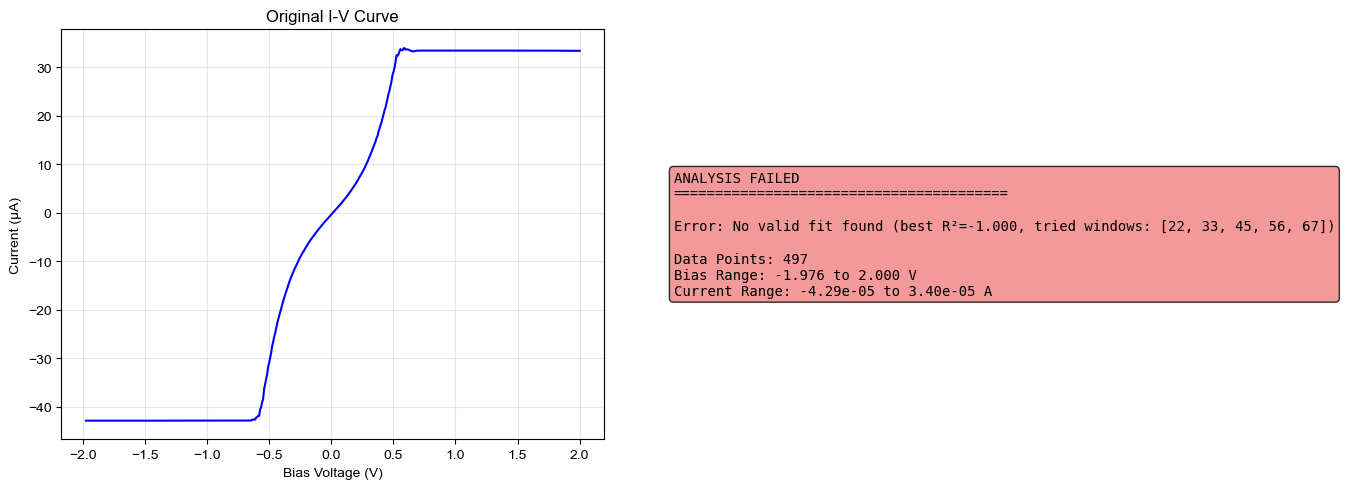

圖表已保存為 'cheung_analysis_pixel_21_65.png'


Parameter,Value,Unit
Ideality Factor (n),nan,
Schottky Barrier (Φ_b),nan,eV
Series Resistance (A),nan,Ω
Series Resistance (B),nan,Ω
R² (Method A),0.0000,
R² (Method B),0.0000,
Fit Range,nan-nan,V
Fit Quality,POOR,
Window Size,0,points
Data Points,497,


In [73]:
import numpy as np

# 1. 正確計算面積
d_nm = 25  # 直徑 25 nm
d_cm = d_nm * 1e-7  # 轉換為 cm
radius_cm = d_cm / 2
area_cm2 = np.pi * (radius_cm ** 2)

#print(f"直徑: {d_nm} nm")
#print(f"面積: {area_cm2:.2e} cm²")

xs, ys = 21, 65
spectrum = h5map.get_spectrum_at_pixel(xs, ys)[3:] 
bias = h5map.bias_vector[3:]

result = advanced_cheung_analysis(bias, spectrum, area_cm2, window_fraction = 0.2)

# 調用函數
fig = plot_cheung_results(bias, spectrum, result)
plt.show()

# 保存圖表
fig.savefig(f'cheung_analysis_pixel_{xs}_{ys}.png', dpi=300, bbox_inches='tight')
print(f"圖表已保存為 'cheung_analysis_pixel_{xs}_{ys}.png'")

display_html_table(result)

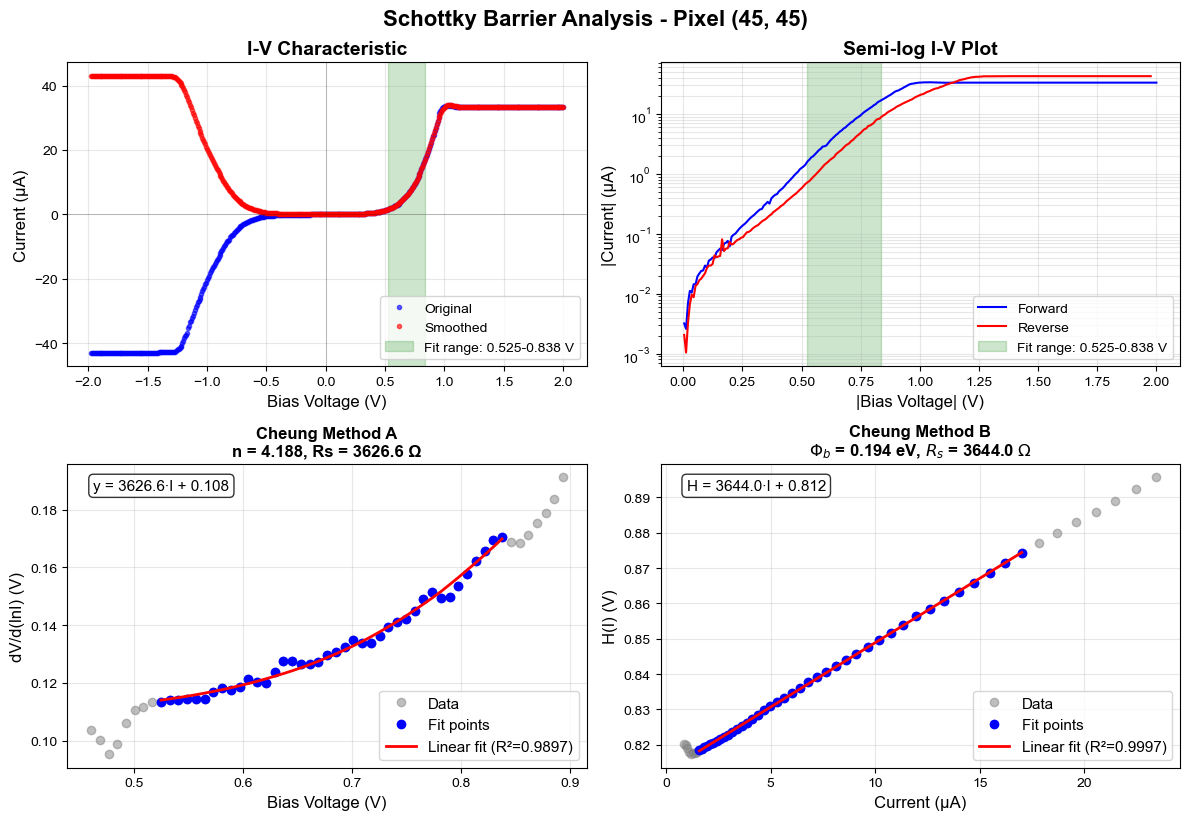

圖表已保存為 'cheung_analysis_pixel_45_45.png'


Parameter,Value,Unit
Ideality Factor (n),4.188,
Schottky Barrier (Φ_b),0.194,eV
Series Resistance (A),3626.6,Ω
Series Resistance (B),3644.0,Ω
R² (Method A),0.9897,
R² (Method B),0.9997,
Fit Range,0.525-0.838,V
Fit Quality,GOOD,
Window Size,40,points
Data Points,497,


In [55]:

xs, ys = 45, 45
spectrum = h5map.get_spectrum_at_pixel(xs, ys)[3:] 
bias = h5map.bias_vector[3:]

result = advanced_cheung_analysis(bias, spectrum, area_cm2)

# 調用函數
fig = plot_cheung_results(bias, spectrum, result)
plt.show()

# 保存圖表
fig.savefig(f'cheung_analysis_pixel_{xs}_{ys}.png', dpi=300, bbox_inches='tight')
print(f"圖表已保存為 'cheung_analysis_pixel_{xs}_{ys}.png'")

display_html_table(result)

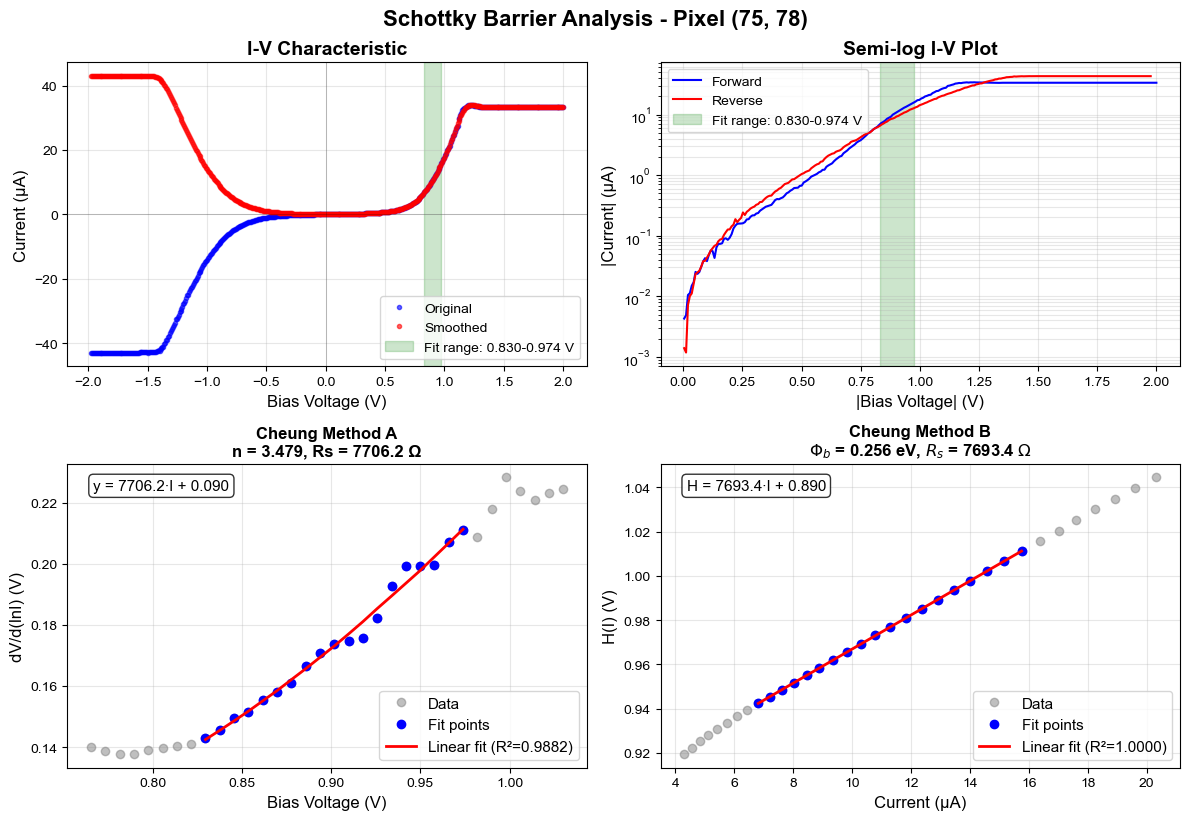

圖表已保存為 'cheung_analysis_pixel_75_78.png'


Parameter,Value,Unit
Ideality Factor (n),3.479,
Schottky Barrier (Φ_b),0.256,eV
Series Resistance (A),7706.2,Ω
Series Resistance (B),7693.4,Ω
R² (Method A),0.9882,
R² (Method B),1.0000,
Fit Range,0.830-0.974,V
Fit Quality,GOOD,
Window Size,19,points
Data Points,497,


In [56]:

# 1. 正確計算面積
d_nm = 25  # 直徑 25 nm
d_cm = d_nm * 1e-7  # 轉換為 cm
radius_cm = d_cm / 2
area_cm2 = np.pi * (radius_cm ** 2)


xs, ys = 75, 78
spectrum = h5map.get_spectrum_at_pixel(xs, ys)[3:] 
bias = h5map.bias_vector[3:]

result = advanced_cheung_analysis(bias, spectrum, area_cm2)

# 調用函數
fig = plot_cheung_results(bias, spectrum, result)
plt.show()

# 保存圖表
fig.savefig(f'cheung_analysis_pixel_{xs}_{ys}.png', dpi=300, bbox_inches='tight')
print(f"圖表已保存為 'cheung_analysis_pixel_{xs}_{ys}.png'")

display_html_table(result)

In [57]:
# 單點分析示例
d_nm = 25
area_cm2 = np.pi * ((d_nm/2) * 1e-7)**2

# 選擇像素點
xs, ys = 75, 78
spectrum = h5map.get_spectrum_at_pixel(xs, ys)[3:] 
bias = h5map.bias_vector[3:]

# 執行分析
result = advanced_cheung_analysis(bias, spectrum, area_cm2=area_cm2)

# 保存結果到 schottky-cheung 目錄
if result['success']:
    saved_paths = save_single_pixel_analysis(
        bias, spectrum, result, xs, ys, 
        output_dir='schottky-cheung'
    )
    
    # 可選：顯示保存的文件列表
    print("\n保存的文件列表:")
    for key, path in saved_paths.items():
        print(f"{key:20}: {path}")
else:
    print("分析失敗，未保存文件")

Created directory: schottky-cheung
Created subdirectory: schottky-cheung/figures
Created subdirectory: schottky-cheung/data
Created subdirectory: schottky-cheung/logs
Created subdirectory: schottky-cheung/reports
圖表已保存到: schottky-cheung/figures/pixel_75_78
數據已保存到: schottky-cheung/data/20260210_092112_pixel_75_78_data.csv
分析結果已保存到: schottky-cheung/data/20260210_092112_pixel_75_78_results.json
摘要報告已保存到: schottky-cheung/reports/20260210_092112_pixel_75_78_summary.txt

所有文件已保存到以下路徑:
  figure_highres: schottky-cheung/figures/pixel_75_78/20260210_092112_pixel_75_78_highres.png
  figure: schottky-cheung/figures/pixel_75_78/20260210_092112_pixel_75_78.png
  figure_pdf: schottky-cheung/figures/pixel_75_78/20260210_092112_pixel_75_78.pdf
  data_csv: schottky-cheung/data/20260210_092112_pixel_75_78_data.csv
  results_json: schottky-cheung/data/20260210_092112_pixel_75_78_results.json
  report_txt: schottky-cheung/reports/20260210_092112_pixel_75_78_summary.txt
  log: schottky-cheung/logs/20260210

In [ ]:

# --------------------------------------------------
# 全圖分析示例

# 生成全圖分析結果
analysis_results = generate_schottky_maps(h5map, area_cm2)

# 保存全圖分析結果
target_bias = 1.0
saved_paths, output_dir = save_full_map_analysis(
    h5map, analysis_results, target_bias,
    output_dir='schottky-cheung'
)

# 顯示保存的目錄結構
print(f"\n生成的目錄結構:")
for root, dirs, files in os.walk(output_dir):
    level = root.replace(output_dir, '').count(os.sep)
    indent = ' ' * 2 * level
    print(f'{indent}{os.path.basename(root)}/')
    subindent = ' ' * 2 * (level + 1)
    for file in files[:5]:  # 只顯示前5個文件
        print(f'{subindent}{file}')
    if len(files) > 5:
        print(f'{subindent}... and {len(files)-5} more files')

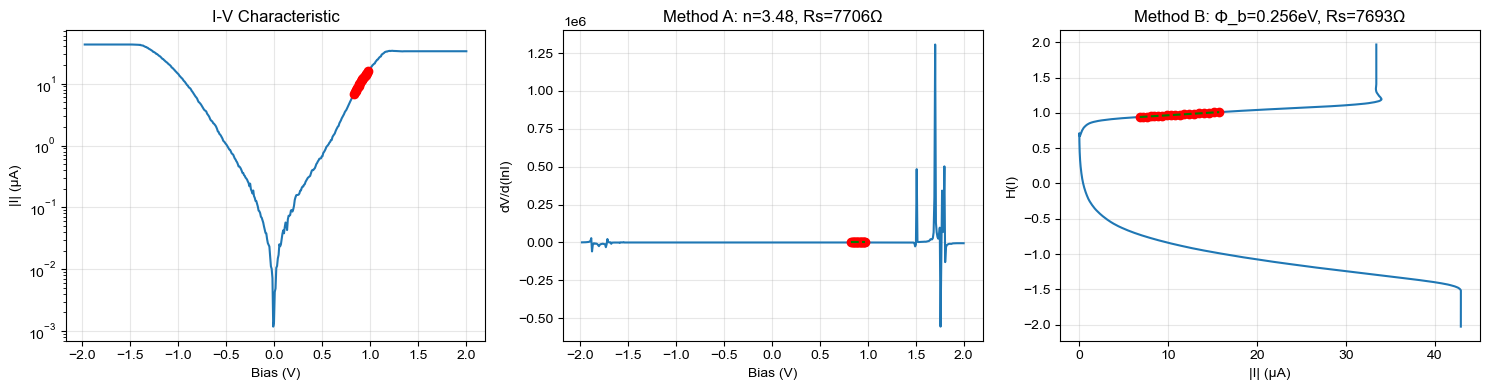

In [30]:
def plot_cheung_simple(bias, current, result):
    """簡化版可視化"""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    # 1. I-V 曲線
    axes[0].semilogy(bias, np.abs(current) * 1e6)
    if result['success']:
        axes[0].semilogy(bias[result['indices']], np.abs(current[result['indices']]) * 1e6, 'ro')
    axes[0].set_xlabel('Bias (V)')
    axes[0].set_ylabel('|I| (µA)')
    axes[0].set_title('I-V Characteristic')
    axes[0].grid(True, alpha=0.3)
    
    # 2. 方法 A
    axes[1].plot(bias, result['y_a'])
    if result['success']:
        axes[1].plot(bias[result['indices']], result['y_a'][result['indices']], 'ro')
        # 添加擬合線
        I_fit = result['I_smooth'][result['indices']]
        y_fit = result['Rs_a'] * I_fit + result['n'] * 8.617e-5 * 300
        axes[1].plot(bias[result['indices']], y_fit, 'g--')
    axes[1].set_xlabel('Bias (V)')
    axes[1].set_ylabel('dV/d(lnI)')
    axes[1].set_title(f'Method A: n={result["n"]:.2f}, Rs={result["Rs_a"]:.0f}Ω')
    axes[1].grid(True, alpha=0.3)
    
    # 3. 方法 B
    axes[2].plot(np.abs(result['I_smooth']) * 1e6, result['H_I'])
    if result['success']:
        axes[2].plot(np.abs(result['I_smooth'][result['indices']]) * 1e6, 
                    result['H_I'][result['indices']], 'ro')
        # 添加擬合線
        H_fit = result['Rs_b'] * I_fit + result['n'] * result['phi_b']
        axes[2].plot(np.abs(I_fit) * 1e6, H_fit, 'g--')
    axes[2].set_xlabel('|I| (µA)')
    axes[2].set_ylabel('H(I)')
    axes[2].set_title(f'Method B: Φ_b={result["phi_b"]:.3f}eV, Rs={result["Rs_b"]:.0f}Ω')
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    return fig

# 使用簡化版
fig_simple = plot_cheung_simple(bias, spectrum, result)
plt.show()

## SBH Mapper by Cheung Method

In [36]:
h5map.print_usage()

HDF5Analyzer 使用指南

📁 數據屬性:
----------------------------------------
  • filepath: 未加載或不可用
  • metadata: 未加載或不可用
  • current_map: 未加載或不可用
  • bias_vector: 未加載或不可用

⚙️ 主要方法:
----------------------------------------
  • load_metadata(): 加載元數據
  • load_current_map(): 加載電流映射
  • load_bias_vector(): 加載偏壓序列
  • load_all_data(): 加載所有數據
  • get_data_info(): 獲取數據信息
  • print_usage(): 顯示使用指南
  • create_slice_viewer(): 創建切片查看器 (需要額外導入)

🔧 數據操作示例:
----------------------------------------
  # 創建分析器並加載數據
  analyzer = HDF5Analyzer('data.h5')
  
  # 訪問數據屬性
  current_map = analyzer.current_map  # 3D電流數據
  bias_voltage = analyzer.bias_vector  # 偏壓序列
  pixels_x = analyzer.metadata.x_pixels  # X像素數
  
  # 獲取特定偏壓的切片
  bias_index = 250
  current_slice = analyzer.current_map[bias_index, :]
  
  # 重塑為2D圖像
  current_2d = current_slice.reshape(analyzer.metadata.y_pixels, analyzer.metadata.x_pixels)
  
  # 獲取特定像素的I-V曲線
  pixel_x, pixel_y = 50, 50
  pixel_index = pixel_y * analyzer.metadata.x_pixels + pixel_x
  iv

In [42]:
h5map.metadata

HDF5Metadata(bias_points=500, x_pixels=100, y_pixels=100, x_range=1.999998e-06, y_range=1.9999969999999996e-06, experiment_type='Bias-Spectroscopy-Current-Map-fwd', unit='m', raw_metadata={'ExpDate': '08.05.2024', 'dataSize': 500, 'lineofHeader': 19})

In [41]:
pixels_x = h5map.metadata.x_pixels
pixels_x

100

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm # 用來顯示進度條，因為 10000 點需要時間

def generate_schottky_maps(h5map, area_cm2):
    """
    計算全區域的 SBH, n, Rs Maps
    """
    bias_vec = h5map.bias_vector
    # 獲取正確的形狀
    if len(h5map.current_map.shape) == 2:
        # 形狀應該是 (bias_points, total_pixels)
        total_pixels = h5map.current_map.shape[1]
    elif len(h5map.current_map.shape) == 3:
        # 形狀可能是 (rows, cols, bias_points) 或 (bias_points, rows, cols)
        total_pixels = h5map.current_map.shape[1] * h5map.current_map.shape[2]
    else:
        raise ValueError(f"Unexpected current_map shape: {h5map.current_map.shape}")
    
    # 獲取像素尺寸
    xpixels = h5map.metadata.x_pixels
    ypixels = h5map.metadata.y_pixels
    
    # 檢查一致性
    if xpixels * ypixels != total_pixels:
        print(f"Warning: Metadata says {xpixels}x{ypixels}={xpixels*ypixels} pixels, but data has {total_pixels}")
        # 嘗試自動推斷
        xpixels = int(np.sqrt(total_pixels))
        ypixels = total_pixels // xpixels
    
    # 初始化空的 Map (使用 NaN)
    sbh_map = np.full(total_pixels, np.nan)
    n_map = np.full(total_pixels, np.nan)
    rs_map = np.full(total_pixels, np.nan)
    r2_map = np.full(total_pixels, np.nan)  # 新增：記錄擬合質量
    success_map = np.zeros(total_pixels, dtype=bool)  # 新增：記錄是否成功
    
    print(f"Starting Cheung Analysis for {total_pixels} pixels ({xpixels}x{ypixels})...")
    
    for i in tqdm(range(total_pixels), desc="Processing pixels"):
        # 提取該像素點的完整 I-V 曲線
        if len(h5map.current_map.shape) == 2:
            current_iv = h5map.current_map[:, i]
        elif len(h5map.current_map.shape) == 3:
            # 假設形狀是 (rows, cols, bias_points)
            row = i // h5map.current_map.shape[1]
            col = i % h5map.current_map.shape[1]
            current_iv = h5map.current_map[row, col, :]
        
        # 執行 Cheung 分析
        res = advanced_cheung_analysis(bias_vec, current_iv, area_cm2)
        
        if res['success']:
            sbh_map[i] = res['phi_b']
            n_map[i] = res['n']
            rs_map[i] = res['Rs_a']
            r2_map[i] = res['r2_a']
            success_map[i] = True
        else:
            # 可選：記錄失敗原因
            pass
    
    # Reshape 回 2D 矩陣
    sbh_2d = sbh_map.reshape(ypixels, xpixels)
    n_2d = n_map.reshape(ypixels, xpixels)
    rs_2d = rs_map.reshape(ypixels, xpixels)
    r2_2d = r2_map.reshape(ypixels, xpixels)
    success_2d = success_map.reshape(ypixels, xpixels)
    
    # 計算成功率
    success_rate = np.mean(success_map) * 100
    print(f"\nAnalysis completed. Success rate: {success_rate:.1f}%")
    
    return {
        'sbh': sbh_2d,
        'n': n_2d,
        'rs': rs_2d,
        'r2': r2_2d,
        'success': success_2d,
        'success_rate': success_rate,
        'shape': (ypixels, xpixels)
    }
    

In [32]:
def plot_analysis_maps(h5map, analysis_results, target_bias):
    """
    繪製多個分析圖
    """
    # 獲取電流圖 - 修正這裡的錯誤
    try:
        # 方法1: 使用h5map的方法獲取電流
        curr_1d = h5map.get_current_at_bias(target_bias)
        # 重塑為2D形狀
        curr_2d = h5map.reshape_to_2d(curr_1d)
    except (AttributeError, TypeError):
        # 方法2: 手動獲取和重塑
        # 找到最接近的偏壓點
        bias_vec = h5map.bias_vector
        idx = np.argmin(np.abs(bias_vec - target_bias))
        print(f"Using bias point {idx}: {bias_vec[idx]:.3f} V")
        
        # 獲取該偏壓下的電流
        if len(h5map.current_map.shape) == 2:
            # 形狀為 (bias_points, total_pixels)
            curr_1d = h5map.current_map[idx, :]
        elif len(h5map.current_map.shape) == 3:
            # 形狀為 (rows, cols, bias_points)
            curr_1d = h5map.current_map[:, :, idx].flatten()
        else:
            raise ValueError(f"Unexpected current_map shape: {h5map.current_map.shape}")
        
        # 使用分析結果的形狀進行重塑
        shape = analysis_results['shape']
        curr_2d = curr_1d.reshape(shape)
    
    # 獲取分析結果
    sbh_2d = analysis_results['sbh']
    n_2d = analysis_results['n']
    rs_2d = analysis_results['rs']
    r2_2d = analysis_results['r2']
    success_2d = analysis_results['success']
    
    # 創建圖表
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    
    # 1. 電流圖 (左上)
    # 檢查並確保 curr_2d 是正確的2D形狀
    if curr_2d.ndim != 2:
        print(f"Warning: curr_2d has shape {curr_2d.shape}, reshaping to {analysis_results['shape']}")
        curr_2d = curr_2d.reshape(analysis_results['shape'])
    
    im1 = axes[0, 0].imshow(np.abs(curr_2d), cmap='viridis', origin='lower')
    plt.colorbar(im1, ax=axes[0, 0], shrink = 0.3, aspect = 7)
    axes[0, 0].set_title(f'Current Map at {target_bias:.3f} V\n(Shape: {curr_2d.shape})')
    axes[0, 0].set_xlabel('X (pixels)')
    axes[0, 0].set_ylabel('Y (pixels)')
    
    # 2. SBH 圖 (中上)
    cmap_sbh = plt.cm.plasma.copy()
    cmap_sbh.set_bad(color='gray', alpha=0.3)
    
    # 只顯示成功的點
    sbh_to_plot = np.where(success_2d, sbh_2d, np.nan)
    
    # 計算顏色範圍（排除極端值）
    sbh_valid = sbh_to_plot[~np.isnan(sbh_to_plot)]
    if len(sbh_valid) > 0:
        vmin, vmax = np.percentile(sbh_valid, [5, 95])
    else:
        vmin, vmax = 0, 1
    
    im2 = axes[0, 1].imshow(sbh_to_plot, cmap=cmap_sbh, 
                           vmin=vmin, vmax=vmax, origin='lower')
    plt.colorbar(im2, ax=axes[0, 1], shrink = 0.3, aspect = 7)
    
    sbh_mean = np.nanmean(sbh_to_plot)
    sbh_std = np.nanstd(sbh_to_plot)
    axes[0, 1].set_title(f'Schottky Barrier Height\n(Φ_b = {sbh_mean:.3f} ± {sbh_std:.3f} eV)')
    axes[0, 1].set_xlabel('X (pixels)')
    axes[0, 1].set_ylabel('Y (pixels)')
    
    # 3. 理想因子圖 (右上)
    cmap_n = plt.cm.coolwarm.copy()
    cmap_n.set_bad(color='gray', alpha=0.3)
    
    n_to_plot = np.where(success_2d, n_2d, np.nan)
    # 計算合適的顯示範圍
    n_valid = n_to_plot[~np.isnan(n_to_plot)]
    if len(n_valid) > 0:
        n_vmin, n_vmax = np.percentile(n_valid, [5, 95])
        n_vmin = max(1, n_vmin * 0.8)  # 確保最小值至少為1
        n_vmax = min(10, n_vmax * 1.2)  # 限制最大值
    else:
        n_vmin, n_vmax = 1, 10
    
    im3 = axes[0, 2].imshow(n_to_plot, cmap=cmap_n, 
                           vmin=n_vmin, vmax=n_vmax, origin='lower')
    plt.colorbar(im3, ax=axes[0, 2], shrink = 0.3, aspect = 7)
    
    n_mean = np.nanmean(n_to_plot)
    n_median = np.nanmedian(n_to_plot)
    axes[0, 2].set_title(f'Ideality Factor\n(mean={n_mean:.2f}, median={n_median:.2f})')
    axes[0, 2].set_xlabel('X (pixels)')
    axes[0, 2].set_ylabel('Y (pixels)')
    
    # 4. 串聯電阻圖 (左下)
    cmap_rs = plt.cm.magma.copy()
    cmap_rs.set_bad(color='gray', alpha=0.3)
    
    rs_to_plot = np.where(success_2d, rs_2d, np.nan)
    
    # 只取正值的電阻
    rs_valid = rs_to_plot[~np.isnan(rs_to_plot) & (rs_to_plot > 0)]
    
    if len(rs_valid) > 0:
        # 使用對數尺度
        rs_valid_log = np.log10(rs_valid)
        vmin_r, vmax_r = np.percentile(rs_valid_log, [5, 95])
        
        # 創建對數標準化
        from matplotlib.colors import LogNorm
        norm = LogNorm(vmin=10**vmin_r, vmax=10**vmax_r)
        
        im4 = axes[1, 0].imshow(rs_to_plot, cmap=cmap_rs, norm=norm, origin='lower')
        plt.colorbar(im4, ax=axes[1, 0], shrink = 0.3, aspect = 7)
    else:
        im4 = axes[1, 0].imshow(rs_to_plot, cmap=cmap_rs, origin='lower')
        plt.colorbar(im4, ax=axes[1, 0], shrink = 0.3, aspect = 7)
    
    rs_median = np.nanmedian(rs_to_plot)
    axes[1, 0].set_title(f'Series Resistance\n(median={rs_median:.1f} Ω)')
    axes[1, 0].set_xlabel('X (pixels)')
    axes[1, 0].set_ylabel('Y (pixels)')
    
    # 5. R² 擬合質量圖 (中下)
    cmap_r2 = plt.cm.RdYlGn.copy()
    cmap_r2.set_bad(color='gray', alpha=0.3)
    
    r2_to_plot = np.where(success_2d, r2_2d, np.nan)
    im5 = axes[1, 1].imshow(r2_to_plot, cmap=cmap_r2, 
                           vmin=0.9, vmax=1.0, origin='lower')
    plt.colorbar(im5, ax=axes[1, 1], shrink = 0.3, aspect = 7)
    
    r2_mean = np.nanmean(r2_to_plot)
    axes[1, 1].set_title(f'Fit Quality (R²)\n(mean={r2_mean:.4f})')
    axes[1, 1].set_xlabel('X (pixels)')
    axes[1, 1].set_ylabel('Y (pixels)')
    
    # 6. 成功率/統計圖 (右下)
    axes[1, 2].axis('off')
    
    # 統計信息
    total_pixels = success_2d.size
    success_count = np.sum(success_2d)
    success_rate = analysis_results['success_rate']
    
    # 計算各種統計量
    sbh_stats = f"{np.nanmean(sbh_to_plot):.4f} ± {np.nanstd(sbh_to_plot):.4f} eV"
    n_stats = f"{np.nanmean(n_to_plot):.3f} ± {np.nanstd(n_to_plot):.3f}"
    rs_stats = f"{np.nanmedian(rs_to_plot):.0f} Ω"
    
    stats_text = (
        f"ANALYSIS STATISTICS\n"
        f"═══════════════════\n\n"
        f"Total Pixels: {total_pixels}\n"
        f"Successful Fits: {success_count} ({success_rate:.1f}%)\n"
        f"Failed Fits: {total_pixels - success_count}\n\n"
        
        f"SBH (Φ_b) STATISTICS\n"
        f"═══════════════════\n"
        f"Mean ± Std: {sbh_stats}\n"
        f"Min: {np.nanmin(sbh_to_plot):.4f} eV\n"
        f"Max: {np.nanmax(sbh_to_plot):.4f} eV\n"
        f"Median: {np.nanmedian(sbh_to_plot):.4f} eV\n\n"
        
        f"IDEALITY FACTOR STATS\n"
        f"═════════════════════\n"
        f"Mean ± Std: {n_stats}\n"
        f"Median: {np.nanmedian(n_to_plot):.3f}\n"
        f"Range: {np.nanmin(n_to_plot):.2f}-{np.nanmax(n_to_plot):.2f}\n\n"
        
        f"SERIES RESISTANCE\n"
        f"═════════════════\n"
        f"Median: {rs_stats}\n"
        f"Mean: {np.nanmean(rs_to_plot):.0f} Ω\n"
        f"Range: {np.nanmin(rs_to_plot):.0f}-{np.nanmax(rs_to_plot):.0f} Ω\n\n"
        
        f"FIT QUALITY\n"
        f"═══════════\n"
        f"Mean R²: {r2_mean:.4f}\n"
        f"R² > 0.99: {np.sum(r2_to_plot > 0.99)} pixels\n"
        f"R² > 0.95: {np.sum(r2_to_plot > 0.95)} pixels"
    )
    
    axes[1, 2].text(0.05, 0.95, stats_text, 
                   fontfamily='monospace', fontsize=9,
                   verticalalignment='top', transform=axes[1, 2].transAxes,
                   bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.8))
    
    plt.tight_layout()
    plt.show()
    
    return fig, axes

In [18]:
# 假設 h5map 已經加載
# 計算面積
d_nm = 25
radius_cm = (d_nm / 2) * 1e-7
area_cm2 = np.pi * radius_cm**2

print(f"Contact diameter: {d_nm} nm")
print(f"Contact area: {area_cm2:.2e} cm²")
print(f"Bias points: {len(h5map.bias_vector)}")
print(f"Bias range: {h5map.bias_vector[0]:.3f} to {h5map.bias_vector[-1]:.3f} V")

# 生成映射圖
analysis_results = generate_schottky_maps(h5map, area_cm2)

Contact diameter: 25 nm
Contact area: 4.91e-12 cm²
Bias points: 500
Bias range: -2.000 to 2.000 V


NameError: name 'generate_schottky_maps' is not defined

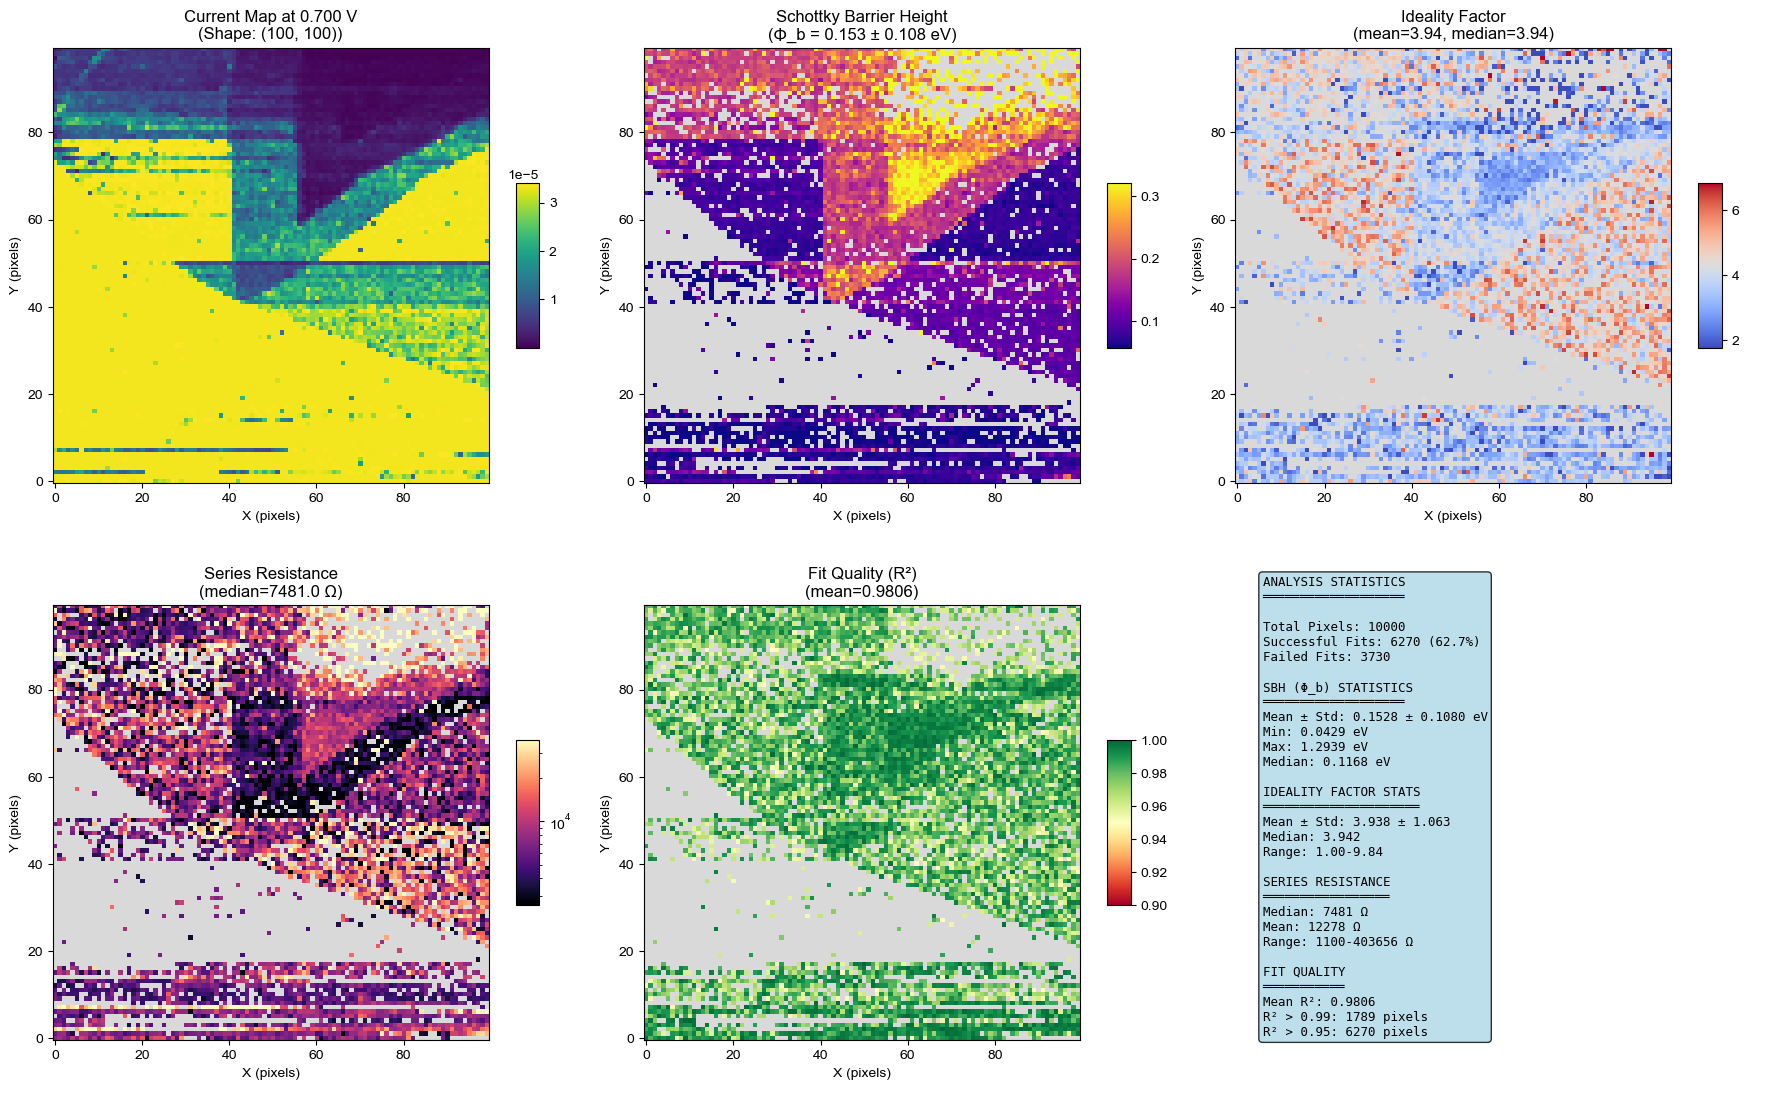

In [37]:
# 繪製映射圖
target_bias = 0.7 
fig_maps = plot_analysis_maps(h5map, analysis_results, target_bias)

In [87]:
# 繪製直方圖
fig_hists = plot_histograms(analysis_results)

# 可選：保存結果
np.savez('cheung_analysis_results.npz',
         sbh_map=analysis_results['sbh'],
         n_map=analysis_results['n'],
         rs_map=analysis_results['rs'],
         r2_map=analysis_results['r2'],
         success_map=analysis_results['success'],
         success_rate=analysis_results['success_rate'])

print("Analysis completed and results saved.")

NameError: name 'plot_histograms' is not defined